In [49]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# Load output CSV file
log_file = Path("../data/repeat_era_bucket_entropy_log.csv")  # Adjust path as needed
df = pd.read_csv(log_file)

# Parse JSON strings and flatten all individual sub-buckets into a DataFrame
all_buckets = []
for raw_str in df["bucket_details_raw"].dropna():
    buckets = json.loads(raw_str)
    all_buckets.extend(buckets)

df_buckets = pd.DataFrame(all_buckets)

print(f"Total evaluated sub-buckets: {len(df_buckets):,}")
print(
    f"Sub-buckets with N > 2: {(df_buckets['n'] > 2).sum():,} "
    f"({(df_buckets['n'] > 2).mean() * 100:.1f}%)"
)

Total evaluated sub-buckets: 179,421
Sub-buckets with N > 2: 73,444 (40.9%)


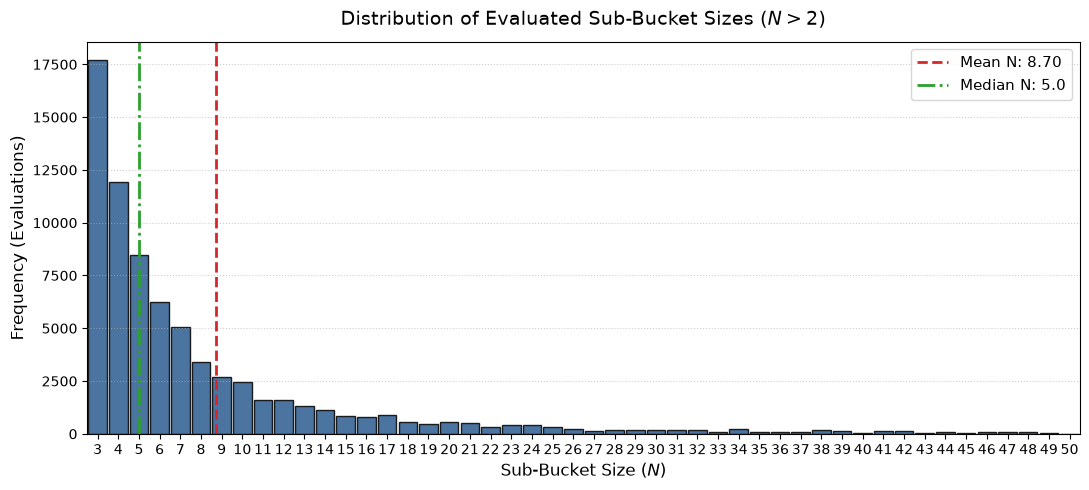

In [50]:
# Filter out N = 1 and N = 2
filtered_sizes = df_buckets[df_buckets["n"] > 2]["n"]

plt.figure(figsize=(11, 5))

# Integer-aligned bin boundaries centered on discrete bucket sizes N
max_display_n = min(int(np.percentile(filtered_sizes, 99)), 50)
bins = np.arange(2.5, max_display_n + 1.5, 1)

plt.hist(
    filtered_sizes,
    bins=bins,
    edgecolor="black",
    color="#2b5c8f",
    alpha=0.85,
    rwidth=0.9,
)

# Statistics
mean_n = filtered_sizes.mean()
median_n = filtered_sizes.median()

plt.axvline(
    mean_n,
    color="#d62728",
    linestyle="--",
    linewidth=2,
    label=f"Mean N: {mean_n:.2f}",
)
plt.axvline(
    median_n,
    color="#2ca02c",
    linestyle="-.",
    linewidth=2,
    label=f"Median N: {median_n:.1f}",
)

plt.title(
    "Distribution of Evaluated Sub-Bucket Sizes ($N > 2$)",
    fontsize=14,
    pad=12,
)
plt.xlabel("Sub-Bucket Size ($N$)", fontsize=12)
plt.ylabel("Frequency (Evaluations)", fontsize=12)
plt.xticks(np.arange(3, max_display_n + 1, 1))
plt.xlim(2.5, max_display_n + 0.5)
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

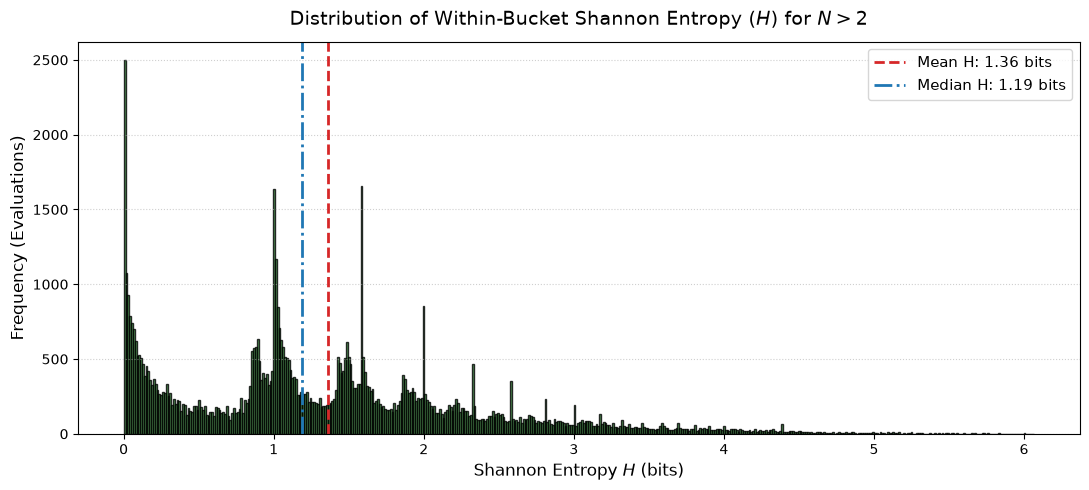

Sub-buckets evaluated (N > 2): 73,444
Mean Entropy: 1.3617 bits | Median Entropy: 1.1904 bits


In [51]:
# Filter out buckets where N <= 2
filtered_df = df_buckets[df_buckets["n"] > 2]
filtered_entropies = filtered_df["h"]

plt.figure(figsize=(11, 5))

# Plot histogram of Shannon entropy values for N > 2
plt.hist(
    filtered_entropies,
    bins=500,
    edgecolor="black",
    color="#2e7d32",
    alpha=0.8,
)

# Statistics
mean_h = filtered_entropies.mean()
median_h = filtered_entropies.median()

plt.axvline(
    mean_h,
    color="#d62728",
    linestyle="--",
    linewidth=2,
    label=f"Mean H: {mean_h:.2f} bits",
)
plt.axvline(
    median_h,
    color="#1f77b4",
    linestyle="-.",
    linewidth=2,
    label=f"Median H: {median_h:.2f} bits",
)

plt.title(
    "Distribution of Within-Bucket Shannon Entropy ($H$) for $N > 2$",
    fontsize=14,
    pad=12,
)
plt.xlabel("Shannon Entropy $H$ (bits)", fontsize=12)
plt.ylabel("Frequency (Evaluations)", fontsize=12)
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

print(f"Sub-buckets evaluated (N > 2): {len(filtered_entropies):,}")
print(f"Mean Entropy: {mean_h:.4f} bits | Median Entropy: {median_h:.4f} bits")

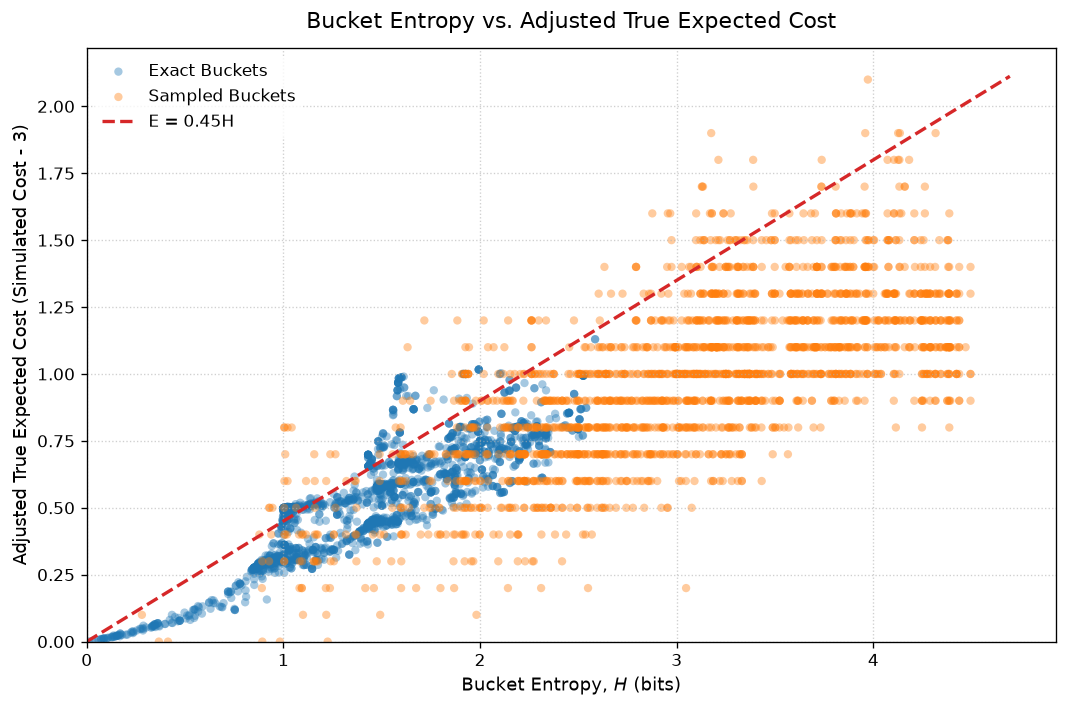

In [52]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# 1. Load data
file_path = Path('../data/sampled_bucket_evaluations.csv')
df = pd.read_csv(file_path)

# 2. Calculate adjusted cost (subtract 3 for turns 3+ cost)
df['true_cost_adj'] = df['true_expected_cost'] - 3.0

# 3. Separate exact vs sampled buckets
exact_mask = df['bucket_raw_size'] == df['bucket_eff_size']
df_exact = df[exact_mask]
df_sampled = df[~exact_mask]

# 4. Setup plot
plt.figure(figsize=(9, 6), dpi=120)

# Scatter plot: Exact Buckets
plt.scatter(
    df_exact['bucket_entropy'],
    df_exact['true_cost_adj'],
    alpha=0.4,
    color='#1f77b4',
    edgecolors='none',
    s=25,
    label='Exact Buckets'
)

# Scatter plot: Sampled Buckets
plt.scatter(
    df_sampled['bucket_entropy'],
    df_sampled['true_cost_adj'],
    alpha=0.4,
    color='#ff7f0e',
    edgecolors='none',
    s=25,
    label='Sampled Buckets'
)

# Reference Line: E = 0.45 * H
max_h = max(df['bucket_entropy'].max() + 0.2, 1.0)
h_vals = np.linspace(0, max_h, 100)
e_vals = 0.45 * h_vals

plt.plot(
    h_vals,
    e_vals,
    color='#d62728',
    linestyle='--',
    linewidth=2,
    label='E = 0.45H'
)

# Formatting
plt.title('Bucket Entropy vs. Adjusted True Expected Cost', fontsize=13, pad=12)
plt.xlabel('Bucket Entropy, $H$ (bits)', fontsize=11)
plt.ylabel('Adjusted True Expected Cost (Simulated Cost - 3)', fontsize=11)

# Enforce non-negative axis limits
plt.xlim(left=0)
plt.ylim(bottom=0)

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', edgecolor='none', loc='upper left')

plt.tight_layout()
plt.show()

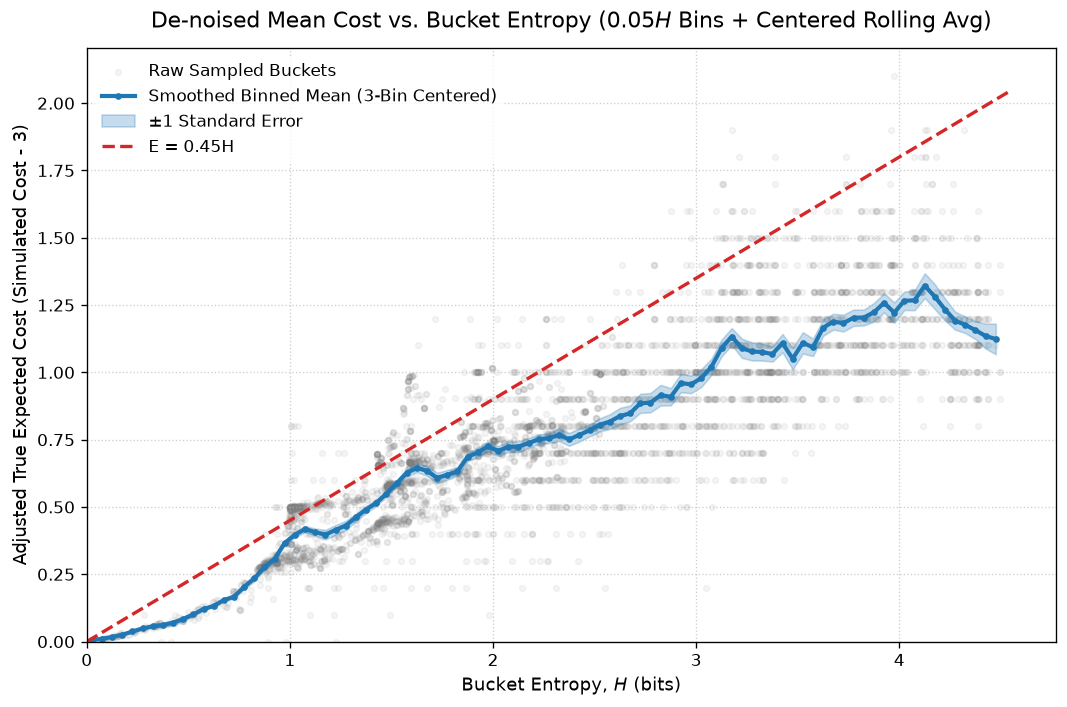

In [53]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Define 0.05 H bins
bin_width = 0.05
max_h = df['bucket_entropy'].max() + bin_width
bins = np.arange(0, max_h, bin_width)

df['h_bin'] = pd.cut(
    df['bucket_entropy'],
    bins=bins,
    labels=(bins[:-1] + bin_width / 2)
).astype(float)

# 2. Aggregate per bin
binned_df = df.groupby('h_bin').agg(
    cost_mean=('true_cost_adj', 'mean'),
    cost_sem=('true_cost_adj', 'sem'),
    count=('true_cost_adj', 'count')
).reset_index()

binned_clean = binned_df[binned_df['count'] >= 1].copy()

# 3. Apply Centered Rolling Average across 3 adjacent bins (0.15 H total span)
# min_periods=1 ensures endpoints use 2-bin averages without NaN truncation
window_size = 3

binned_clean['cost_smooth'] = binned_clean['cost_mean'].rolling(
    window=window_size, center=True, min_periods=1
).mean()

binned_clean['sem_smooth'] = binned_clean['cost_sem'].rolling(
    window=window_size, center=True, min_periods=1
).mean()

# 4. Plot
plt.figure(figsize=(9, 6), dpi=120)

# Faint raw points in background
plt.scatter(
    df['bucket_entropy'],
    df['true_cost_adj'],
    alpha=0.08,
    color='gray',
    s=12,
    label='Raw Sampled Buckets'
)

# Smoothed Binned Mean Line
plt.plot(
    binned_clean['h_bin'],
    binned_clean['cost_smooth'],
    color='#1f77b4',
    linewidth=2.5,
    marker='o',
    markersize=3,
    label='Smoothed Binned Mean (3-Bin Centered)'
)

# Smoothed Standard Error Band
plt.fill_between(
    binned_clean['h_bin'],
    binned_clean['cost_smooth'] - binned_clean['sem_smooth'],
    binned_clean['cost_smooth'] + binned_clean['sem_smooth'],
    color='#1f77b4',
    alpha=0.25,
    label='±1 Standard Error'
)

# Reference Line E = 0.45H
h_vals = np.linspace(0, max_h, 100)
plt.plot(
    h_vals,
    0.45 * h_vals,
    color='#d62728',
    linestyle='--',
    linewidth=2,
    label='E = 0.45H'
)

# Formatting
plt.title('De-noised Mean Cost vs. Bucket Entropy ($0.05 H$ Bins + Centered Rolling Avg)', fontsize=13, pad=12)
plt.xlabel('Bucket Entropy, $H$ (bits)', fontsize=11)
plt.ylabel('Adjusted True Expected Cost (Simulated Cost - 3)', fontsize=11)

plt.xlim(left=0)
plt.ylim(bottom=0)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', edgecolor='none', loc='upper left')

plt.tight_layout()
plt.show()

C:\Users\edwar\AppData\Local\Temp\ipykernel_10056\3053888644.py:19: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_exact = df_filtered[exact_mask]
C:\Users\edwar\AppData\Local\Temp\ipykernel_10056\3053888644.py:20: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_sampled = df_filtered[~exact_mask]


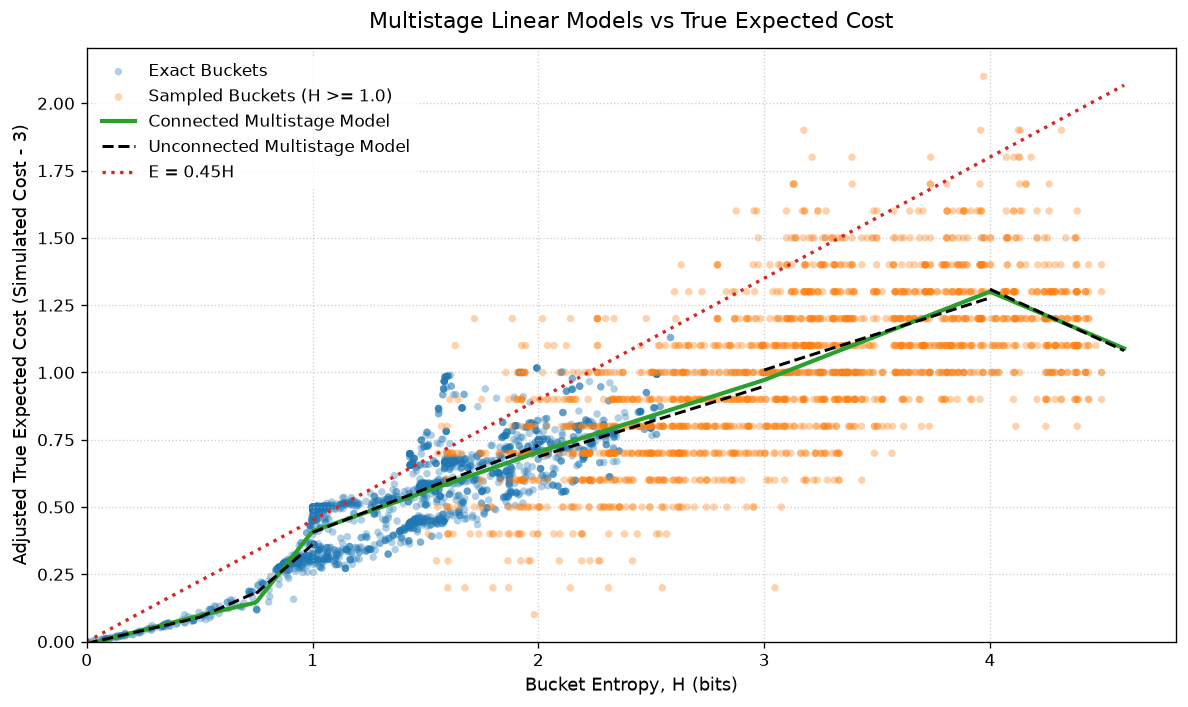

In [54]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# 1. Load data
file_path = Path('../data/sampled_bucket_evaluations.csv')
df = pd.read_csv(file_path)

# 2. Adjust cost metric (turns 3+)
df['true_cost_adj'] = df['true_expected_cost'] - 3.0

# 3. Identify exact vs sampled buckets
exact_mask = df['bucket_raw_size'] == df['bucket_eff_size']

# Filter: Remove sampled buckets where H < 1.0 (keep only exact ones for H < 1.0)
df_filtered = df[exact_mask | (df['bucket_entropy'] >= 1.5)].copy()

df_exact = df_filtered[exact_mask]
df_sampled = df_filtered[~exact_mask]

# 4. Define stage boundaries (knots)
boundaries = [0.0, 0.5, 0.75, 1.0, 2.0, 3.0, 4.0]
max_h = df_filtered['bucket_entropy'].max() + 0.1

# ==========================================
# MODEL A: Continuous (Endpoints Connected)
# ==========================================
x_data = df_filtered['bucket_entropy'].values
y_data = df_filtered['true_cost_adj'].values

# Construct continuous piecewise basis matrix: f(x) = b0 + b1*x + b2*max(0, x-0.5) + ...
X_cont = [np.ones_like(x_data), x_data]
for k in boundaries[1:]:
    X_cont.append(np.maximum(0, x_data - k))
X_cont = np.column_stack(X_cont)

beta_cont, _, _, _ = np.linalg.lstsq(X_cont, y_data, rcond=None)

# Generate grid prediction for continuous line
x_grid = np.linspace(0, max_h, 500)
X_grid = [np.ones_like(x_grid), x_grid]
for k in boundaries[1:]:
    X_grid.append(np.maximum(0, x_grid - k))
X_grid = np.column_stack(X_grid)
y_cont_pred = X_grid @ beta_cont

# ==========================================
# PLOTTING
# ==========================================
plt.figure(figsize=(10, 6), dpi=120)

# Scatter: Blue for Exact, Orange for Sampled
plt.scatter(
    df_exact['bucket_entropy'],
    df_exact['true_cost_adj'],
    alpha=0.35,
    color='#1f77b4',
    edgecolors='none',
    s=20,
    label='Exact Buckets'
)

plt.scatter(
    df_sampled['bucket_entropy'],
    df_sampled['true_cost_adj'],
    alpha=0.35,
    color='#ff7f0e',
    edgecolors='none',
    s=20,
    label='Sampled Buckets (H >= 1.0)'
)

# Plot Model A: Continuous (Green Solid)
plt.plot(
    x_grid,
    y_cont_pred,
    color='#2ca02c',
    linewidth=2.5,
    label='Connected Multistage Model'
)

# ==========================================
# MODEL B: Discontinuous (Endpoints Unconnected)
# ==========================================
all_bounds = boundaries + [max_h]
for i in range(len(all_bounds) - 1):
    low, high = all_bounds[i], all_bounds[i + 1]
    mask = (df_filtered['bucket_entropy'] >= low) & (df_filtered['bucket_entropy'] < high)
    sub = df_filtered[mask]
    
    if len(sub) > 1:
        slope, intercept = np.polyfit(sub['bucket_entropy'], sub['true_cost_adj'], 1)
        x_seg = np.linspace(low, high, 50)
        y_seg = slope * x_seg + intercept
        
        seg_label = 'Unconnected Multistage Model' if i == 0 else None
        plt.plot(
            x_seg,
            y_seg,
            color='black',
            linestyle='--',
            linewidth=1.8,
            label=seg_label
        )

# Reference Line E = 0.45H
h_ref = np.linspace(0, max_h, 100)
plt.plot(
    h_ref,
    0.45 * h_ref,
    color='#d62728',
    linestyle=':',
    linewidth=2,
    label='E = 0.45H'
)

# Formatting (using raw strings to prevent escape sequence warnings)
plt.title(r'Multistage Linear Models vs True Expected Cost', fontsize=13, pad=12)
plt.xlabel(r'Bucket Entropy, H (bits)', fontsize=11)
plt.ylabel(r'Adjusted True Expected Cost (Simulated Cost - 3)', fontsize=11)

plt.xlim(left=0)
plt.ylim(bottom=0)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', edgecolor='none', loc='upper left')

plt.tight_layout()
plt.show()

=== BREAKDOWN BY INTEGER ENTROPY RANGE ===
Range    | Count  | Lin RMSE  | Log RMSE  | Lin R2   | Log R2  
--------------------------------------------------------------
1 - 2    | 1525   | 0.1336    | 0.1383    | 0.3461   | 0.2990  
2 - 3    | 1006   | 0.1763    | 0.1859    | 0.1357   | 0.0393  
3 - 4    | 904    | 0.2264    | 0.2330    | 0.1024   | 0.0490  
4+       | 279    | 0.2566    | 0.2158    | -0.4878  | -0.0525 


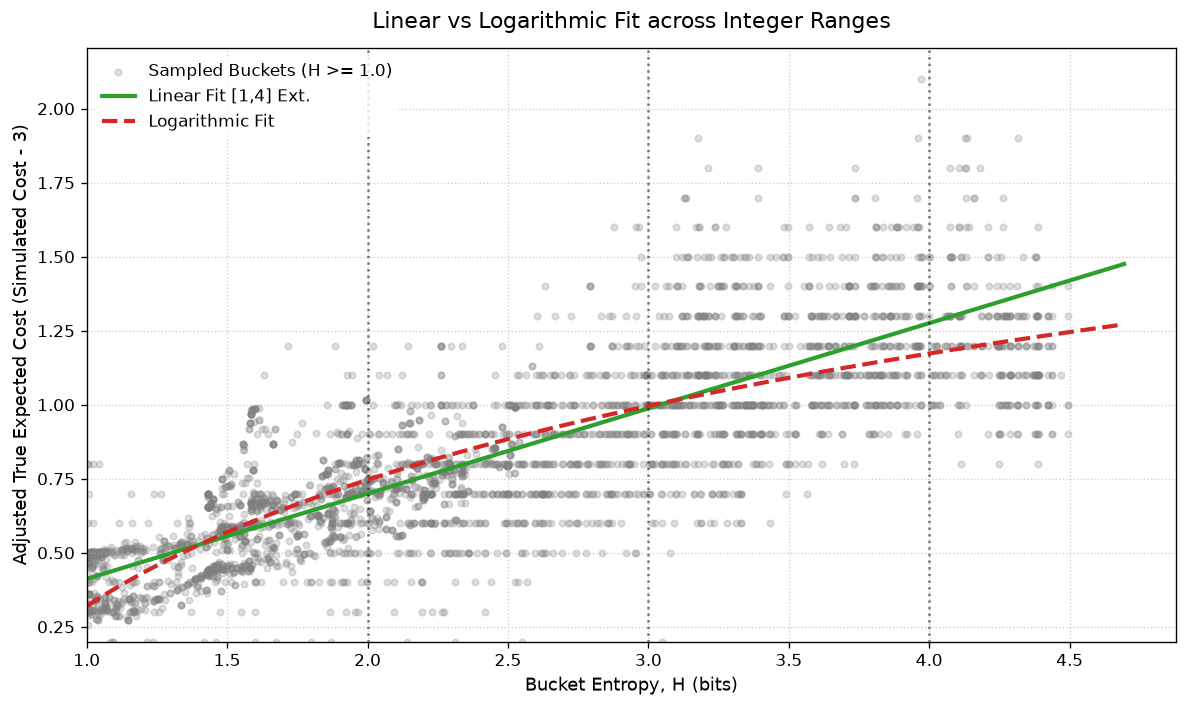

In [55]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# 1. Load data
file_path = Path('../data/sampled_bucket_evaluations.csv')
df = pd.read_csv(file_path)

# 2. Adjust cost metric (turns 3+)
df['true_cost_adj'] = df['true_expected_cost'] - 3.0

# 3. Filter for H >= 1.0
exact_mask = df['bucket_raw_size'] == df['bucket_eff_size']
df_filtered = df[exact_mask | (df['bucket_entropy'] >= 1.0)].copy()
df_h1 = df_filtered[df_filtered['bucket_entropy'] >= 1.0].copy()

# 4. Model Fits
# Linear Fit trained on 1.0 <= H <= 4.0
df_h_1_4 = df_h1[df_h1['bucket_entropy'] <= 4.0]
m_lin, c_lin = np.polyfit(df_h_1_4['bucket_entropy'], df_h_1_4['true_cost_adj'], 1)

# Logarithmic Fit trained on all H >= 1.0
b_log, a_log = np.polyfit(np.log(df_h1['bucket_entropy']), df_h1['true_cost_adj'], 1)

# Generate predictions on full dataset H >= 1.0
df_h1['y_lin'] = m_lin * df_h1['bucket_entropy'] + c_lin
df_h1['y_log'] = a_log + b_log * np.log(df_h1['bucket_entropy'])

# 5. Evaluate Performance by Integer Range
ranges = [
    ('1 - 2', 1.0, 2.0),
    ('2 - 3', 2.0, 3.0),
    ('3 - 4', 3.0, 4.0),
    ('4+',   4.0, 999.0)
]

print("=== BREAKDOWN BY INTEGER ENTROPY RANGE ===")
print(f"{'Range':<8} | {'Count':<6} | {'Lin RMSE':<9} | {'Log RMSE':<9} | {'Lin R2':<8} | {'Log R2':<8}")
print("-" * 62)

for label, low, high in ranges:
    sub = df_h1[(df_h1['bucket_entropy'] >= low) & (df_h1['bucket_entropy'] < high)]
    count = len(sub)
    
    if count > 0:
        y_act = sub['true_cost_adj'].values
        y_lin = sub['y_lin'].values
        y_log = sub['y_log'].values
        
        rmse_lin = np.sqrt(np.mean((y_act - y_lin) ** 2))
        rmse_log = np.sqrt(np.mean((y_act - y_log) ** 2))
        
        ss_tot = np.sum((y_act - np.mean(y_act)) ** 2)
        
        if ss_tot > 1e-9:
            r2_lin = 1 - (np.sum((y_act - y_lin) ** 2) / ss_tot)
            r2_log = 1 - (np.sum((y_act - y_log) ** 2) / ss_tot)
        else:
            r2_lin, r2_log = 0.0, 0.0
            
        print(f"{label:<8} | {count:<6} | {rmse_lin:<9.4f} | {rmse_log:<9.4f} | {r2_lin:<8.4f} | {r2_log:<8.4f}")

# 6. Plot with Zone Boundaries
plt.figure(figsize=(10, 6), dpi=120)

max_h = df_h1['bucket_entropy'].max() + 0.2
h_grid = np.linspace(1.0, max_h, 300)

y_lin_grid = m_lin * h_grid + c_lin
y_log_grid = a_log + b_log * np.log(h_grid)

# Background scatter points
plt.scatter(
    df_h1['bucket_entropy'],
    df_h1['true_cost_adj'],
    alpha=0.25,
    color='gray',
    s=15,
    label='Sampled Buckets (H >= 1.0)'
)

# Plot Model Lines
plt.plot(h_grid, y_lin_grid, color='#2ca02c', linewidth=2.5, label='Linear Fit [1,4] Ext.')
plt.plot(h_grid, y_log_grid, color='#d62728', linestyle='--', linewidth=2.5, label='Logarithmic Fit')

# Draw vertical segment boundary lines
for boundary in [2.0, 3.0, 4.0]:
    plt.axvline(x=boundary, color='black', linestyle=':', alpha=0.5)

# Formatting
plt.title('Linear vs Logarithmic Fit across Integer Ranges', fontsize=13, pad=12)
plt.xlabel('Bucket Entropy, H (bits)', fontsize=11)
plt.ylabel('Adjusted True Expected Cost (Simulated Cost - 3)', fontsize=11)

plt.xlim(left=1.0)
plt.ylim(bottom=0.2)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', edgecolor='none', loc='upper left')

plt.tight_layout()
plt.show()

=== UNCONNECTED SEGMENT FITS (0 <= H <= 1.0) ===
Interval       | Count  | Slope    | Intercept 
-----------------------------------------------
0.000 - 0.250 | 55     | 0.1615   | -0.0029   
0.250 - 0.500 | 45     | 0.1981   | -0.0079   
0.500 - 0.750 | 41     | 0.3419   | -0.0802   
0.750 - 0.875 | 62     | 1.0667   | -0.6420   
0.875 - 1.000 | 157    | 0.8675   | -0.5004   


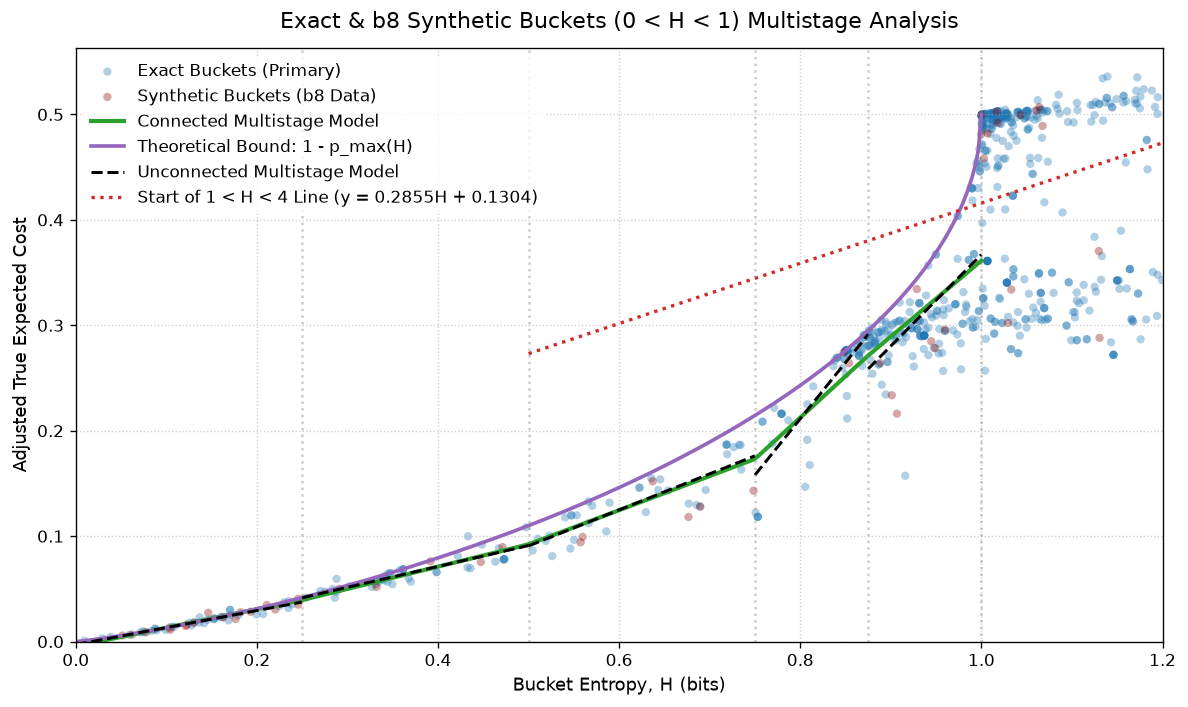

In [56]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# 1. Load primary dataset
path_primary = Path('../data/sampled_bucket_evaluations.csv')
df = pd.read_csv(path_primary)
df['true_cost_adj'] = df['true_expected_cost'] - 3.0

# Filter exact buckets only from primary dataset
exact_mask = df['bucket_raw_size'] == df['bucket_eff_size']
df_exact = df[exact_mask].copy()

# 2. Load b8 synthetic dataset (Subtract 1 from true_expected_cost)
path_b8 = Path('../data/synthetic_bucket_data_b8.csv')
df_b8 = pd.read_csv(path_b8)
df_b8['true_cost_adj'] = df_b8['true_expected_cost'] - 1.0

# 3. Combine exact primary buckets and b8 synthetic buckets for fitting H <= 1.0
df_exact_fit = df_exact[(df_exact['bucket_entropy'] >= 0.0) & (df_exact['bucket_entropy'] <= 1.0)][['bucket_entropy', 'true_cost_adj']]
df_b8_fit = df_b8[(df_b8['bucket_entropy'] >= 0.0) & (df_b8['bucket_entropy'] <= 1.0)][['bucket_entropy', 'true_cost_adj']]

df_fit = pd.concat([df_exact_fit, df_b8_fit], ignore_index=True)

x_data = df_fit['bucket_entropy'].values
y_data = df_fit['true_cost_adj'].values

# ==========================================
# MODEL A: Continuous Multistage
# Knots: 0.25, 0.50, 0.75, 0.875, 1.00 (Split 0.75-1.0 stage into two)
# ==========================================
knots = [0.25, 0.50, 0.75, 0.875, 1.00]

X_cont = [np.ones_like(x_data), x_data]
for k in knots[:-1]:
    X_cont.append(np.maximum(0, x_data - k))
X_cont = np.column_stack(X_cont)

beta_cont, _, _, _ = np.linalg.lstsq(X_cont, y_data, rcond=None)

x_grid_fit = np.linspace(0.0, 1.0, 200)
X_grid_fit = [np.ones_like(x_grid_fit), x_grid_fit]
for k in knots[:-1]:
    X_grid_fit.append(np.maximum(0, x_grid_fit - k))
X_grid_fit = np.column_stack(X_grid_fit)
y_cont_pred = X_grid_fit @ beta_cont

# ==========================================
# THEORETICAL BOUND: 1 - p_max(H)
# ==========================================
p_fine = np.linspace(0.5, 1.0 - 1e-9, 2000)
h_fine = -p_fine * np.log2(p_fine) - (1.0 - p_fine) * np.log2(1.0 - p_fine)

h_bound_grid = np.linspace(0.0, 1.0, 300)
p_max_interp = np.interp(h_bound_grid, h_fine[::-1], p_fine[::-1])
y_bound_pred = 1.0 - p_max_interp

# ==========================================
# PLOTTING
# ==========================================
plt.figure(figsize=(10, 6), dpi=120)

# 1. Exact Primary Buckets
df_exact_plot = df_exact[df_exact['bucket_entropy'] <= 1.2]
plt.scatter(
    df_exact_plot['bucket_entropy'],
    df_exact_plot['true_cost_adj'],
    alpha=0.35,
    color='#1f77b4',
    edgecolors='none',
    s=25,
    label='Exact Buckets (Primary)'
)

# 2. b8 Synthetic Buckets (Darker Blue)
df_b8_plot = df_b8[df_b8['bucket_entropy'] <= 1.2]
plt.scatter(
    df_b8_plot['bucket_entropy'],
    df_b8_plot['true_cost_adj'],
    alpha=0.35,
    color='#8b0000',
    edgecolors='none',
    s=25,
    label='Synthetic Buckets (b8 Data)'
)

# 3. Connected Multistage Model
plt.plot(
    x_grid_fit,
    y_cont_pred,
    color='#2ca02c',
    linewidth=2.5,
    label='Connected Multistage Model'
)

# 4. Theoretical Bound Line
plt.plot(
    h_bound_grid,
    y_bound_pred,
    color='#9467bd',
    linestyle='-',
    linewidth=2.2,
    label='Theoretical Bound: 1 - p_max(H)'
)

# ==========================================
# MODEL B: Discontinuous Segments
# ==========================================
intervals = [(0.0, 0.25), (0.25, 0.50), (0.50, 0.75), (0.75, 0.875), (0.875, 1.00)]

print("=== UNCONNECTED SEGMENT FITS (0 <= H <= 1.0) ===")
print(f"{'Interval':<14} | {'Count':<6} | {'Slope':<8} | {'Intercept':<10}")
print("-" * 47)

for i, (low, high) in enumerate(intervals):
    if i == len(intervals) - 1:
        mask = (df_fit['bucket_entropy'] >= low) & (df_fit['bucket_entropy'] <= high)
    else:
        mask = (df_fit['bucket_entropy'] >= low) & (df_fit['bucket_entropy'] < high)
        
    sub = df_fit[mask]
    
    if len(sub) > 1:
        slope, intercept = np.polyfit(sub['bucket_entropy'], sub['true_cost_adj'], 1)
        x_seg = np.linspace(low, high, 50)
        y_seg = slope * x_seg + intercept
        
        print(f"{low:.3f} - {high:.3f} | {len(sub):<6} | {slope:<8.4f} | {intercept:<10.4f}")
        
        seg_label = 'Unconnected Multistage Model' if i == 0 else None
        plt.plot(
            x_seg,
            y_seg,
            color='black',
            linestyle='--',
            linewidth=1.8,
            label=seg_label
        )

# 5. Reference Line: Start of 1 < H < 4 Line
h_ref = np.linspace(0.5, 1.2, 100)
y_ref = 0.2855 * h_ref + 0.1304
plt.plot(
    h_ref,
    y_ref,
    color='#d62728',
    linestyle=':',
    linewidth=2,
    label='Start of 1 < H < 4 Line (y = 0.2855H + 0.1304)'
)

# Vertical boundary lines at knots
for boundary in knots:
    plt.axvline(x=boundary, color='gray', linestyle=':', alpha=0.4)

# Formatting
plt.title('Exact & b8 Synthetic Buckets (0 < H < 1) Multistage Analysis', fontsize=13, pad=12)
plt.xlabel('Bucket Entropy, H (bits)', fontsize=11)
plt.ylabel('Adjusted True Expected Cost', fontsize=11)

plt.xlim(left=0, right=1.2)
plt.ylim(bottom=0)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', edgecolor='none', loc='upper left')

plt.tight_layout()
plt.show()

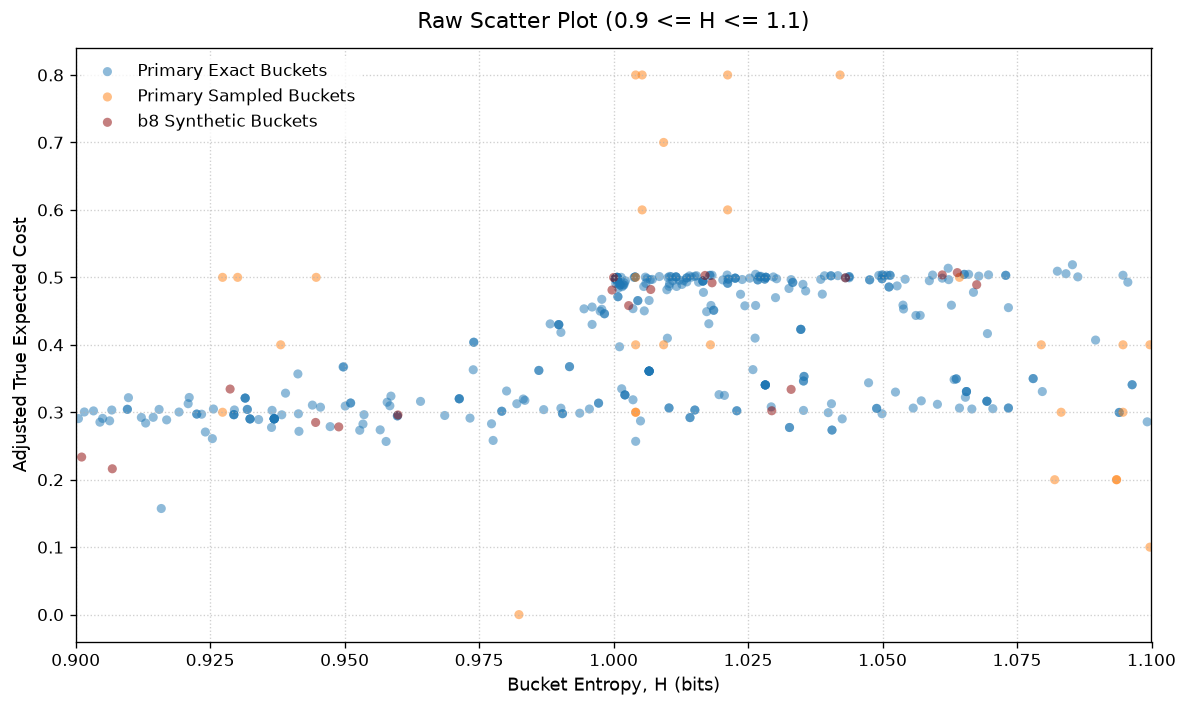

In [57]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# 1. Load primary dataset
path_primary = Path('../data/sampled_bucket_evaluations.csv')
df_primary = pd.read_csv(path_primary)
df_primary['true_cost_adj'] = df_primary['true_expected_cost'] - 3.0

# Filter primary data for 0.9 <= H <= 1.1
df_primary_sub = df_primary[
    (df_primary['bucket_entropy'] >= 0.9) & (df_primary['bucket_entropy'] <= 1.1)
].copy()

# Separate primary into exact vs sampled
exact_mask = df_primary_sub['bucket_raw_size'] == df_primary_sub['bucket_eff_size']
df_primary_exact = df_primary_sub[exact_mask]
df_primary_sampled = df_primary_sub[~exact_mask]

# 2. Load b8 synthetic dataset
path_b8 = Path('../data/synthetic_bucket_data_b8.csv')
df_b8 = pd.read_csv(path_b8)
df_b8['true_cost_adj'] = df_b8['true_expected_cost'] - 1.0

# Filter b8 data for 0.9 <= H <= 1.1
df_b8_sub = df_b8[
    (df_b8['bucket_entropy'] >= 0.9) & (df_b8['bucket_entropy'] <= 1.1)
].copy()

# 3. Setup Plot
plt.figure(figsize=(10, 6), dpi=120)

# Primary Exact Buckets
plt.scatter(
    df_primary_exact['bucket_entropy'],
    df_primary_exact['true_cost_adj'],
    alpha=0.5,
    color='#1f77b4',
    edgecolors='none',
    s=30,
    label='Primary Exact Buckets'
)

# Primary Sampled Buckets (if any exist in range)
if len(df_primary_sampled) > 0:
    plt.scatter(
        df_primary_sampled['bucket_entropy'],
        df_primary_sampled['true_cost_adj'],
        alpha=0.5,
        color='#ff7f0e',
        edgecolors='none',
        s=30,
        label='Primary Sampled Buckets'
    )

# b8 Synthetic Buckets (#8b0000)
plt.scatter(
    df_b8_sub['bucket_entropy'],
    df_b8_sub['true_cost_adj'],
    alpha=0.5,
    color='#8b0000',
    edgecolors='none',
    s=30,
    label='b8 Synthetic Buckets'
)

# Formatting
plt.title('Raw Scatter Plot (0.9 <= H <= 1.1)', fontsize=13, pad=12)
plt.xlabel('Bucket Entropy, H (bits)', fontsize=11)
plt.ylabel('Adjusted True Expected Cost', fontsize=11)

plt.xlim(0.9, 1.1)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', edgecolor='none', loc='upper left')

plt.tight_layout()
plt.show()

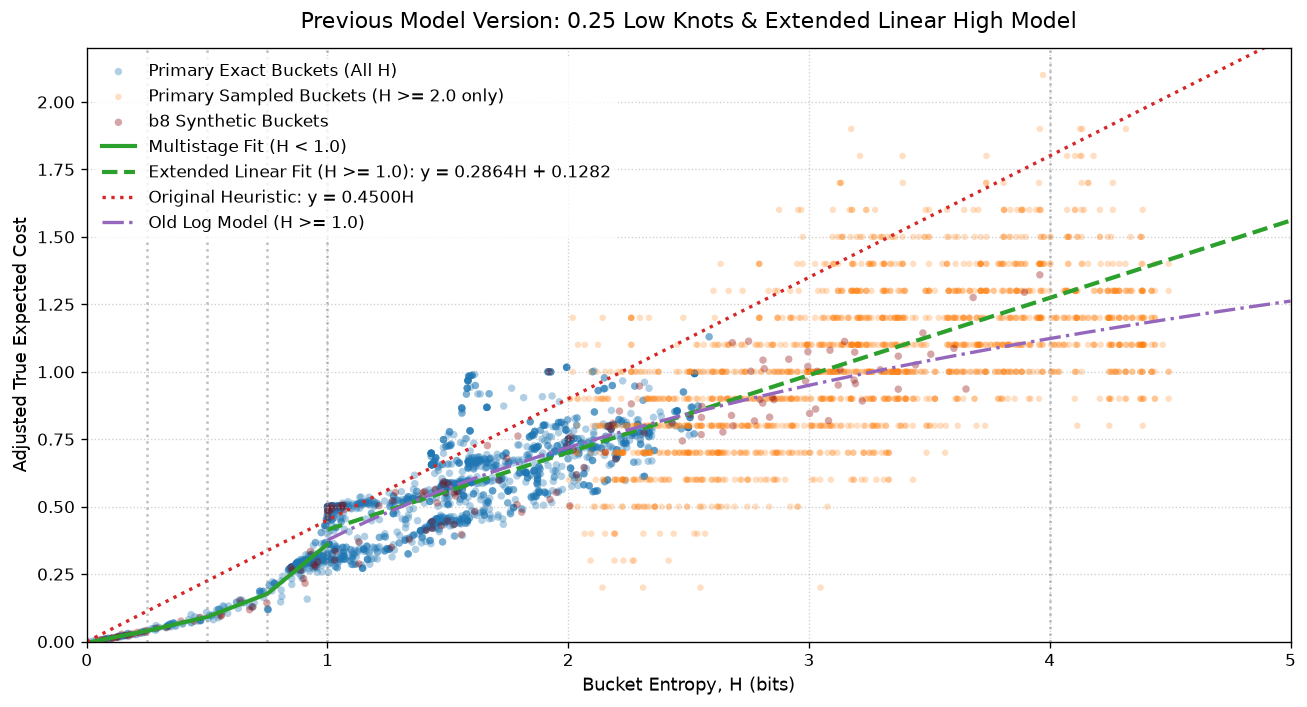

=== PIECEWISE MODEL FORMULAS ===
  0.00 <= H < 0.25 : E_adj = 0.1769 * H + -0.0045
  0.25 <= H < 0.50 : E_adj = 0.2062 * H + -0.0119
  0.50 <= H < 0.75 : E_adj = 0.3437 * H + -0.0806
  0.75 <= H < 1.00 : E_adj = 0.7361 * H + -0.3749
  H >= 1.00        : E_adj = 0.2864 * H + 0.1282

=== OVERALL MODEL PERFORMANCE (ALL FILTERED H >= 0) ===
Model                        | RMSE     | MAE      | R2       | Max Error 
------------------------------------------------------------------------
Extended Linear Model        | 0.1697   | 0.1227   | 0.7661   | 0.8622    
Original Heuristic (0.45H)   | 0.3640   | 0.2843   | -0.0755  | 1.1738    

=== HIGH-ENTROPY MODEL PERFORMANCE COMPARISON (H >= 1.0) ===
Model                        | RMSE     | MAE      | R2       | Max Error 
------------------------------------------------------------------------
Extended Linear Fit          | 0.1777   | 0.1329   | 0.6811   | 0.8622    
Original Heuristic (0.45H)   | 0.3799   | 0.3019   | -0.4572  | 1.1738    
Old

In [79]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. DATA PREPARATION & FILTERING
# ==============================================================================
# Identify exact vs sampled buckets in primary dataset
exact_primary_mask = df_primary['bucket_raw_size'] == df_primary['bucket_eff_size']

# Filter out randomly sampled points for H < 2.0 (Keep exact buckets for H < 2.0, keep ALL buckets for H >= 2.0)
df_primary_filtered = df_primary[
    (df_primary['bucket_entropy'] >= 2.0) | exact_primary_mask
].copy()

# Combine primary filtered data with b8 synthetic dataset (b8 data consists of exact H < 1.0 buckets)
df_eval = pd.concat([
    df_primary_filtered[['bucket_entropy', 'true_cost_adj']],
    df_b8[['bucket_entropy', 'true_cost_adj']]
], ignore_index=True)

LOW_KNOTS = [0.25, 0.50, 0.75]

# ==============================================================================
# 2. MODEL FITTING
# ==============================================================================
# A. Fit Low-Entropy Connected Multistage Model (0 <= H < 1.0, Knots at 0.25, 0.50, 0.75)
df_fit_low = df_eval[df_eval['bucket_entropy'] < 1.0]
x_low = df_fit_low['bucket_entropy'].values
y_low = df_fit_low['true_cost_adj'].values

X_low = np.column_stack([
    np.ones_like(x_low),
    x_low,
    np.maximum(0, x_low - 0.25),
    np.maximum(0, x_low - 0.50),
    np.maximum(0, x_low - 0.75)
])

beta_low, _, _, _ = np.linalg.lstsq(X_low, y_low, rcond=None)

# B. Fit High-Entropy Single Linear Model (Trained on 1.0 <= H <= 4.0, extended past 4.5)
df_fit_high = df_eval[(df_eval['bucket_entropy'] >= 1.0) & (df_eval['bucket_entropy'] <= 4.0)]
m_high, c_high = np.polyfit(df_fit_high['bucket_entropy'], df_fit_high['true_cost_adj'], 1)

# ==============================================================================
# 3. PREDICTION FUNCTIONS FOR ALL MODELS
# ==============================================================================
def predict_new_model(h_array):
    """Old Extended Model: Multistage 0.25 knots for H < 1.0, Single Line for H >= 1.0"""
    h_array = np.asarray(h_array, dtype=np.float64)
    y_pred = np.zeros_like(h_array)
    low_mask = h_array < 1.0
    
    # Low H (< 1.0) predictions
    if np.any(low_mask):
        x_sub = h_array[low_mask]
        X_sub = np.column_stack([
            np.ones_like(x_sub),
            x_sub,
            np.maximum(0, x_sub - 0.25),
            np.maximum(0, x_sub - 0.50),
            np.maximum(0, x_sub - 0.75)
        ])
        y_pred[low_mask] = X_sub @ beta_low
        
    # High H (>= 1.0) predictions extended past 4.5
    y_pred[~low_mask] = m_high * h_array[~low_mask] + c_high
    return y_pred

def predict_orig_heuristic(h_array):
    """Original Heuristic: E = 0.45 * H"""
    return 0.45 * h_array

def predict_old_log_model(h_array):
    """Old Logarithmic Model for H >= 1.0: E = 0.1100 + 0.7049 * ln(1 + 0.9169 * (H - 0.5))"""
    return 0.1100 + 0.7049 * np.log(1.0 + 0.9169 * (h_array - 0.5))

# Compute predictions across evaluation dataset
h_eval = df_eval['bucket_entropy'].values
y_actual = df_eval['true_cost_adj'].values

y_pred_new = predict_new_model(h_eval)
y_pred_orig = predict_orig_heuristic(h_eval)

# ==============================================================================
# 4. PLOTTING
# ==============================================================================
plt.figure(figsize=(11, 6), dpi=120)

# Filtered Primary Scatter
df_pri_exact = df_primary[exact_primary_mask]
df_pri_sampled_h2 = df_primary[(~exact_primary_mask) & (df_primary['bucket_entropy'] >= 2.0)]

plt.scatter(
    df_pri_exact['bucket_entropy'],
    df_pri_exact['true_cost_adj'],
    alpha=0.35,
    color='#1f77b4',
    edgecolors='none',
    s=20,
    label='Primary Exact Buckets (All H)'
)

plt.scatter(
    df_pri_sampled_h2['bucket_entropy'],
    df_pri_sampled_h2['true_cost_adj'],
    alpha=0.25,
    color='#ff7f0e',
    edgecolors='none',
    s=15,
    label='Primary Sampled Buckets (H >= 2.0 only)'
)

plt.scatter(
    df_b8['bucket_entropy'],
    df_b8['true_cost_adj'],
    alpha=0.35,
    color='#8b0000',
    edgecolors='none',
    s=20,
    label='b8 Synthetic Buckets'
)

# Plot Model Lines
grid_low = np.linspace(0.0, 0.999, 200)
grid_high = np.linspace(1.0, 5.0, 300)

plt.plot(
    grid_low,
    predict_new_model(grid_low),
    color='#2ca02c',
    linewidth=2.5,
    label='Multistage Fit (H < 1.0)'
)

plt.plot(
    grid_high,
    predict_new_model(grid_high),
    color='#2ca02c',
    linestyle='--',
    linewidth=2.5,
    label=f'Extended Linear Fit (H >= 1.0): y = {m_high:.4f}H + {c_high:.4f}'
)

grid_full = np.linspace(0.0, 5.0, 300)
plt.plot(
    grid_full,
    predict_orig_heuristic(grid_full),
    color='#d62728',
    linestyle=':',
    linewidth=2.0,
    label='Original Heuristic: y = 0.4500H'
)

plt.plot(
    grid_high,
    predict_old_log_model(grid_high),
    color='#9467bd',
    linestyle='-.',
    linewidth=2.0,
    label='Old Log Model (H >= 1.0)'
)

# Vertical boundary lines
for knot in [0.25, 0.50, 0.75, 1.00, 4.00]:
    plt.axvline(x=knot, color='gray', linestyle=':', alpha=0.5)

# Formatting
plt.title('Previous Model Version: 0.25 Low Knots & Extended Linear High Model', fontsize=13, pad=12)
plt.xlabel('Bucket Entropy, H (bits)', fontsize=11)
plt.ylabel('Adjusted True Expected Cost', fontsize=11)

plt.xlim(0.0, 5.0)
plt.ylim(0.0, 2.2)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', edgecolor='none', loc='upper left')

plt.tight_layout()
plt.show()

# ==============================================================================
# 5. METRIC EVALUATION FUNCTIONS & FORMULAS EXTRACTION
# ==============================================================================
def compute_metrics(y_true, y_pred):
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mae = np.mean(np.abs(y_true - y_pred))
    max_err = np.max(np.abs(y_true - y_pred))
    
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - (np.sum((y_true - y_pred) ** 2) / ss_tot) if ss_tot > 1e-9 else 0.0
    return rmse, mae, r2, max_err

# Extract Low-Entropy Piecewise Coefficients
b0, b1, b2, b3, b4 = beta_low
s1, i1 = b1, b0
s2, i2 = b1 + b2, b0 - 0.25 * b2
s3, i3 = b1 + b2 + b3, b0 - 0.25 * b2 - 0.50 * b3
s4, i4 = b1 + b2 + b3 + b4, b0 - 0.25 * b2 - 0.50 * b3 - 0.75 * b4

print("=== PIECEWISE MODEL FORMULAS ===")
print(f"  0.00 <= H < 0.25 : E_adj = {s1:.4f} * H + {i1:.4f}")
print(f"  0.25 <= H < 0.50 : E_adj = {s2:.4f} * H + {i2:.4f}")
print(f"  0.50 <= H < 0.75 : E_adj = {s3:.4f} * H + {i3:.4f}")
print(f"  0.75 <= H < 1.00 : E_adj = {s4:.4f} * H + {i4:.4f}")
print(f"  H >= 1.00        : E_adj = {m_high:.4f} * H + {c_high:.4f}\n")

# --- COMPARISON 1: OVERALL DATASET ---
print("=== OVERALL MODEL PERFORMANCE (ALL FILTERED H >= 0) ===")
print(f"{'Model':<28} | {'RMSE':<8} | {'MAE':<8} | {'R2':<8} | {'Max Error':<10}")
print("-" * 72)

r_new, m_new, r2_new, max_new = compute_metrics(y_actual, y_pred_new)
r_orig, m_orig, r2_orig, max_orig = compute_metrics(y_actual, y_pred_orig)

print(f"{'Extended Linear Model':<28} | {r_new:<8.4f} | {m_new:<8.4f} | {r2_new:<8.4f} | {max_new:<10.4f}")
print(f"{'Original Heuristic (0.45H)':<28} | {r_orig:<8.4f} | {m_orig:<8.4f} | {r2_orig:<8.4f} | {max_orig:<10.4f}\n")

# --- COMPARISON 2: HIGH ENTROPY (H >= 1.0) THREE-WAY COMPARISON ---
mask_h1 = h_eval >= 1.0
y_act_h1 = y_actual[mask_h1]
h_h1 = h_eval[mask_h1]

y_pred_new_h1 = predict_new_model(h_h1)
y_pred_orig_h1 = predict_orig_heuristic(h_h1)
y_pred_old_log_h1 = predict_old_log_model(h_h1)

print("=== HIGH-ENTROPY MODEL PERFORMANCE COMPARISON (H >= 1.0) ===")
print(f"{'Model':<28} | {'RMSE':<8} | {'MAE':<8} | {'R2':<8} | {'Max Error':<10}")
print("-" * 72)

r1, m1, r2_1, max1 = compute_metrics(y_act_h1, y_pred_new_h1)
r2, m2, r2_2, max2 = compute_metrics(y_act_h1, y_pred_orig_h1)
r3, m3, r2_3, max3 = compute_metrics(y_act_h1, y_pred_old_log_h1)

print(f"{'Extended Linear Fit':<28} | {r1:<8.4f} | {m1:<8.4f} | {r2_1:<8.4f} | {max1:<10.4f}")
print(f"{'Original Heuristic (0.45H)':<28} | {r2:<8.4f} | {m2:<8.4f} | {r2_2:<8.4f} | {max2:<10.4f}")
print(f"{'Old Logarithmic Model':<28} | {r3:<8.4f} | {m3:<8.4f} | {r2_3:<8.4f} | {max3:<10.4f}\n")

# --- COMPARISON 3: DETAILED BREAKDOWN BY RANGE ---
ranges = [
    ('0 - 1', 0.0, 1.0),
    ('1 - 2', 1.0, 2.0),
    ('2 - 3', 2.0, 3.0),
    ('3 - 4', 3.0, 4.0),
    ('4+', 4.0, 999.0)
]

print("=== MODEL DETAILED BREAKDOWN BY RANGE ===")
print(f"{'Range':<8} | {'Count':<6} | {'RMSE':<8} | {'MAE':<8} | {'R2':<8} | {'Max Error':<10}")
print("-" * 62)

for label, low, high in ranges:
    sub_mask = (df_eval['bucket_entropy'] >= low) & (df_eval['bucket_entropy'] < high)
    sub_y = df_eval.loc[sub_mask, 'true_cost_adj'].values
    sub_h = df_eval.loc[sub_mask, 'bucket_entropy'].values
    count = len(sub_y)
    
    if count > 0:
        sub_pred = predict_new_model(sub_h)
        r, m, r2_val, max_e = compute_metrics(sub_y, sub_pred)
        print(f"{label:<8} | {count:<6} | {r:<8.4f} | {m:<8.4f} | {r2_val:<8.4f} | {max_e:<10.4f}")

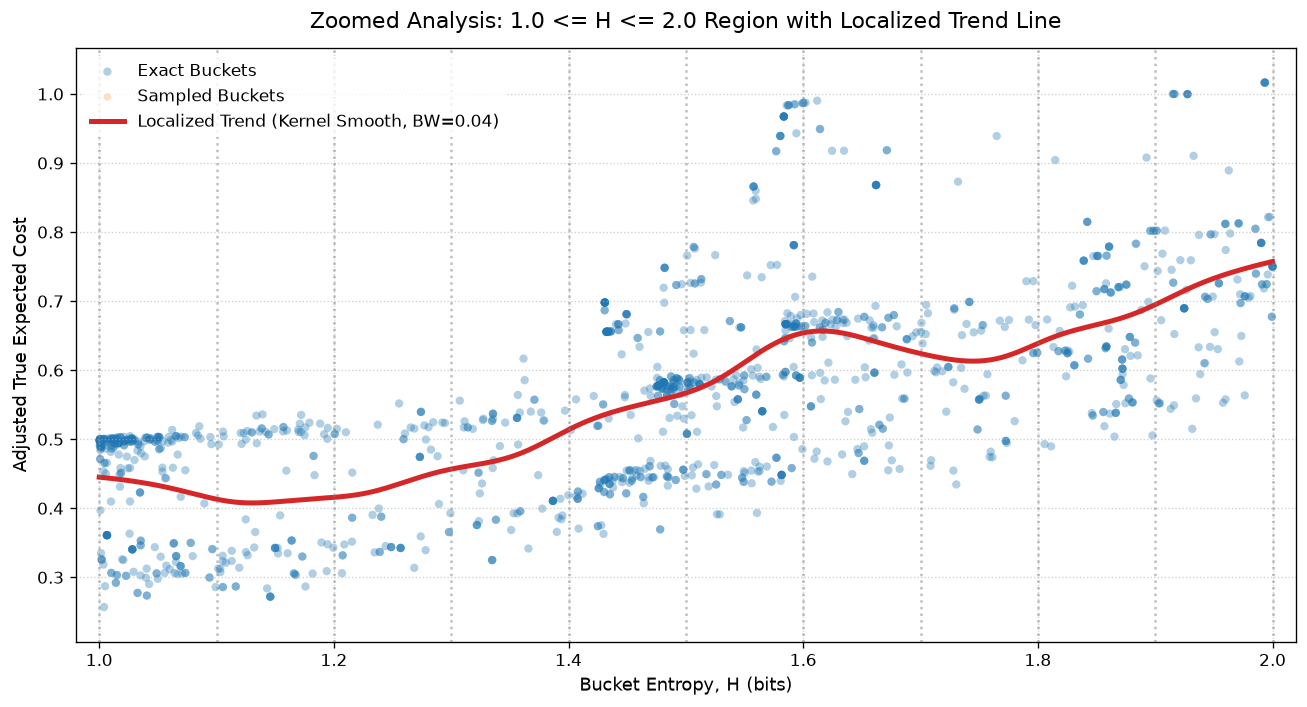

=== FREQUENCY & DENSITY METRICS FOR REGION 1.0 <= H <= 2.0 ===
Total points in region: 1372 (34.51% of overall evaluation dataset)

Sub-Bin    | Count   | % Region  | % Overall  | Mean H   | Mean Cost  | Std Cost
--------------------------------------------------------------------------------
1.0 - 1.1  | 258     | 18.80   % | 6.49     % | 1.0313   | 0.4381     | 0.0799  
1.1 - 1.2  | 88      | 6.41    % | 2.21     % | 1.1476   | 0.4065     | 0.0960  
1.2 - 1.3  | 60      | 4.37    % | 1.51     % | 1.2538   | 0.4321     | 0.0815  
1.3 - 1.4  | 71      | 5.17    % | 1.79     % | 1.3527   | 0.4638     | 0.0756  
1.4 - 1.5  | 238     | 17.35   % | 5.99     % | 1.4592   | 0.5445     | 0.0986  
1.5 - 1.6  | 236     | 17.20   % | 5.94     % | 1.5560   | 0.6250     | 0.1485  
1.6 - 1.7  | 119     | 8.67    % | 2.99     % | 1.6444   | 0.6422     | 0.1281  
1.7 - 1.8  | 71      | 5.17    % | 1.79     % | 1.7485   | 0.6103     | 0.0924  
1.8 - 1.9  | 119     | 8.67    % | 2.99     % | 1.8571   |

In [75]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. DATA ISOLATION FOR REGION 1.0 <= H <= 2.0
# ==============================================================================
mask_1_2 = (df_eval['bucket_entropy'] >= 1.0) & (df_eval['bucket_entropy'] <= 2.0)
df_1_2 = df_eval[mask_1_2].copy().sort_values('bucket_entropy').reset_index(drop=True)

total_eval_count = len(df_eval)
region_count = len(df_1_2)

# ==============================================================================
# 2. LOCALIZED TREND LINE (Gaussian Kernel Smoothing)
# ==============================================================================
# Fine evaluation grid across 1.0 to 2.0
grid_h = np.linspace(1.0, 2.0, 400)
bandwidth = 0.04  # Narrow bandwidth for localized trend sensitivity

smooth_y = []
for h_val in grid_h:
    # Gaussian weights centered on current evaluation point
    weights = np.exp(-0.5 * ((df_1_2['bucket_entropy'] - h_val) / bandwidth) ** 2)
    weight_sum = np.sum(weights)
    if weight_sum > 1e-6:
        smooth_y.append(np.average(df_1_2['true_cost_adj'], weights=weights))
    else:
        smooth_y.append(np.nan)

smooth_y = np.array(smooth_y)

# ==============================================================================
# 3. ZOOMED PLOT (1.0 <= H <= 2.0)
# ==============================================================================
plt.figure(figsize=(11, 6), dpi=120)

# Scatter points in region 1.0 <= H <= 2.0
mask_pri_exact = (df_primary_filtered['bucket_entropy'] >= 1.0) & (df_primary_filtered['bucket_entropy'] <= 2.0) & exact_primary_mask
mask_pri_samp = (df_primary_filtered['bucket_entropy'] >= 1.0) & (df_primary_filtered['bucket_entropy'] <= 2.0) & (~exact_primary_mask)

plt.scatter(
    df_primary_filtered.loc[mask_pri_exact, 'bucket_entropy'],
    df_primary_filtered.loc[mask_pri_exact, 'true_cost_adj'],
    alpha=0.35, color='#1f77b4', edgecolors='none', s=25, label='Exact Buckets'
)

plt.scatter(
    df_primary_filtered.loc[mask_pri_samp, 'bucket_entropy'],
    df_primary_filtered.loc[mask_pri_samp, 'true_cost_adj'],
    alpha=0.25, color='#ff7f0e', edgecolors='none', s=20, label='Sampled Buckets'
)

# Overlay Localized Trend Line
plt.plot(
    grid_h, smooth_y, color='#d62728', linewidth=3.0,
    label=f'Localized Trend (Kernel Smooth, BW={bandwidth})'
)

# Vertical guide lines at 0.1 intervals
for bin_start in np.arange(1.0, 2.1, 0.1):
    plt.axvline(x=bin_start, color='gray', linestyle=':', alpha=0.5)

# Formatting (Plaintext labels only)
plt.title('Zoomed Analysis: 1.0 <= H <= 2.0 Region with Localized Trend Line', fontsize=13, pad=12)
plt.xlabel('Bucket Entropy, H (bits)', fontsize=11)
plt.ylabel('Adjusted True Expected Cost', fontsize=11)
plt.xlim(0.98, 2.02)

if region_count > 0:
    y_min, y_max = df_1_2['true_cost_adj'].min(), df_1_2['true_cost_adj'].max()
    plt.ylim(max(0, y_min - 0.05), y_max + 0.05)

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', edgecolor='none', loc='upper left')

plt.tight_layout()
plt.show()

# ==============================================================================
# 4. FREQUENCY & DENSITY METRICS BREAKDOWN
# ==============================================================================
bins = np.arange(1.0, 2.05, 0.1)
sub_metrics = []

for i in range(len(bins) - 1):
    b_low, b_high = bins[i], bins[i+1]
    if i == len(bins) - 2:
        sub = df_1_2[(df_1_2['bucket_entropy'] >= b_low) & (df_1_2['bucket_entropy'] <= b_high)]
    else:
        sub = df_1_2[(df_1_2['bucket_entropy'] >= b_low) & (df_1_2['bucket_entropy'] < b_high)]
    
    cnt = len(sub)
    pct_region = (cnt / region_count * 100) if region_count > 0 else 0.0
    pct_total = (cnt / total_eval_count * 100) if total_eval_count > 0 else 0.0
    mean_h = sub['bucket_entropy'].mean() if cnt > 0 else 0.0
    mean_cost = sub['true_cost_adj'].mean() if cnt > 0 else 0.0
    std_cost = sub['true_cost_adj'].std() if cnt > 1 else 0.0

    sub_metrics.append({
        'Range': f"{b_low:.1f} - {b_high:.1f}",
        'Count': cnt,
        'Pct_Region': pct_region,
        'Pct_Total': pct_total,
        'Mean_H': mean_h,
        'Mean_Cost': mean_cost,
        'Std_Cost': std_cost
    })

print("=== FREQUENCY & DENSITY METRICS FOR REGION 1.0 <= H <= 2.0 ===")
print(f"Total points in region: {region_count} ({region_count / total_eval_count * 100:.2f}% of overall evaluation dataset)\n")

print(f"{'Sub-Bin':<10} | {'Count':<7} | {'% Region':<9} | {'% Overall':<10} | {'Mean H':<8} | {'Mean Cost':<10} | {'Std Cost':<8}")
print("-" * 80)

for m in sub_metrics:
    print(f"{m['Range']:<10} | {m['Count']:<7} | {m['Pct_Region']:<8.2f}% | {m['Pct_Total']:<9.2f}% | {m['Mean_H']:<8.4f} | {m['Mean_Cost']:<10.4f} | {m['Std_Cost']:<8.4f}")

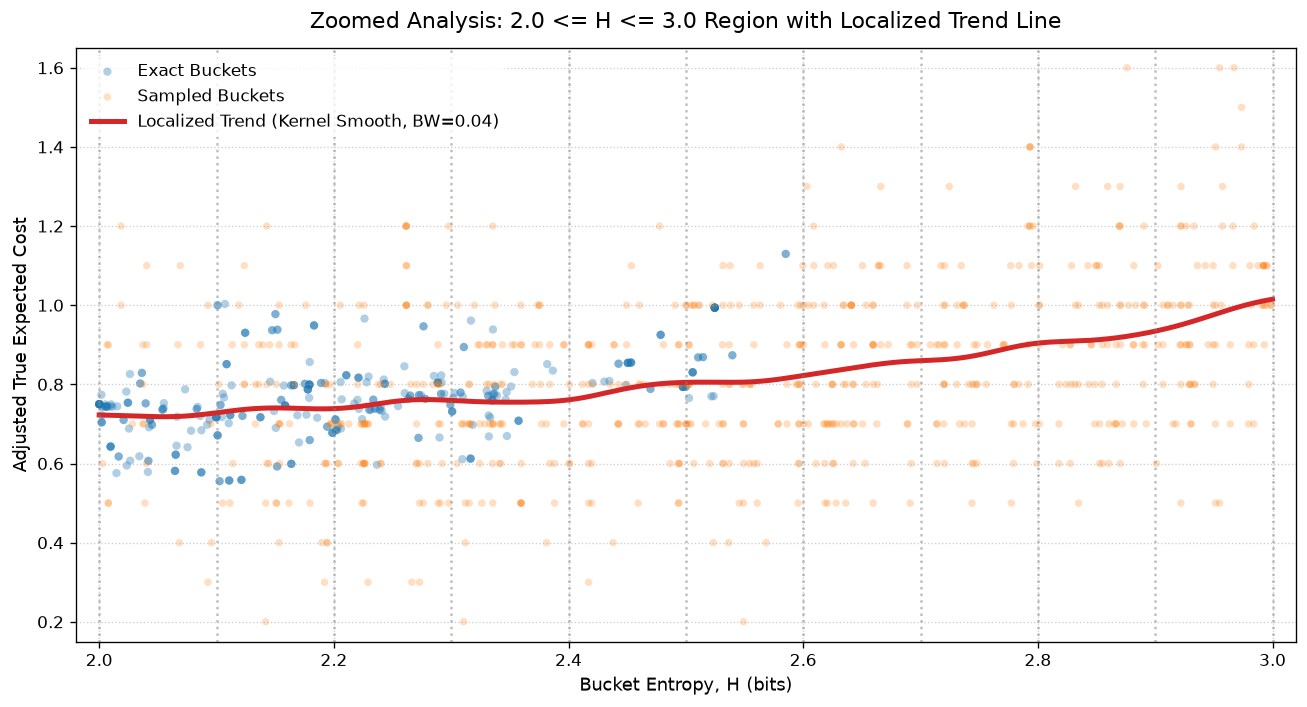

=== FREQUENCY & DENSITY METRICS FOR REGION 2.0 <= H <= 3.0 ===
Total points in region: 1045 (26.28% of overall evaluation dataset)

Sub-Bin    | Count   | % Region  | % Overall  | Mean H   | Mean Cost  | Std Cost
--------------------------------------------------------------------------------
2.0 - 2.1  | 119     | 11.39   % | 2.99     % | 2.0393   | 0.7128     | 0.1266  
2.1 - 2.2  | 148     | 14.16   % | 3.72     % | 2.1517   | 0.7412     | 0.1560  
2.2 - 2.3  | 142     | 13.59   % | 3.57     % | 2.2493   | 0.7630     | 0.1622  
2.3 - 2.4  | 115     | 11.00   % | 2.89     % | 2.3396   | 0.7497     | 0.1516  
2.4 - 2.5  | 90      | 8.61    % | 2.26     % | 2.4581   | 0.7747     | 0.1451  
2.5 - 2.6  | 107     | 10.24   % | 2.69     % | 2.5425   | 0.8127     | 0.1797  
2.6 - 2.7  | 91      | 8.71    % | 2.29     % | 2.6443   | 0.8486     | 0.1947  
2.7 - 2.8  | 72      | 6.89    % | 1.81     % | 2.7535   | 0.8865     | 0.2100  
2.8 - 2.9  | 76      | 7.27    % | 1.91     % | 2.8510   |

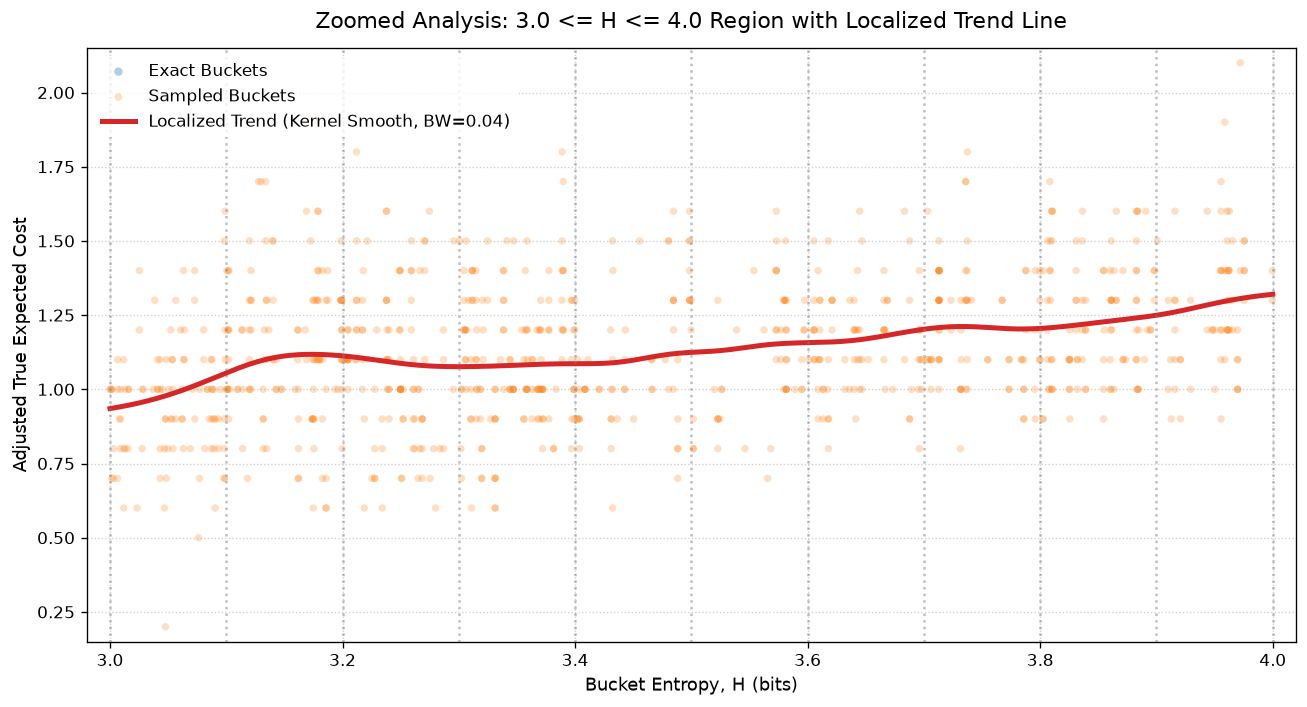

=== FREQUENCY & DENSITY METRICS FOR REGION 3.0 <= H <= 4.0 ===
Total points in region: 927 (23.31% of overall evaluation dataset)

Sub-Bin    | Count   | % Region  | % Overall  | Mean H   | Mean Cost  | Std Cost
--------------------------------------------------------------------------------
3.0 - 3.1  | 106     | 11.43   % | 2.67     % | 3.0528   | 0.9529     | 0.2108  
3.1 - 3.2  | 126     | 13.59   % | 3.17     % | 3.1539   | 1.1299     | 0.2480  
3.2 - 3.3  | 106     | 11.43   % | 2.67     % | 3.2440   | 1.0830     | 0.2539  
3.3 - 3.4  | 150     | 16.18   % | 3.77     % | 3.3481   | 1.0966     | 0.2222  
3.4 - 3.5  | 61      | 6.58    % | 1.53     % | 3.4537   | 1.1061     | 0.2326  
3.5 - 3.6  | 51      | 5.50    % | 1.28     % | 3.5623   | 1.1150     | 0.2102  
3.6 - 3.7  | 83      | 8.95    % | 2.09     % | 3.6449   | 1.1542     | 0.1768  
3.7 - 3.8  | 77      | 8.31    % | 1.94     % | 3.7439   | 1.2104     | 0.1977  
3.8 - 3.9  | 100     | 10.79   % | 2.52     % | 3.8480   | 

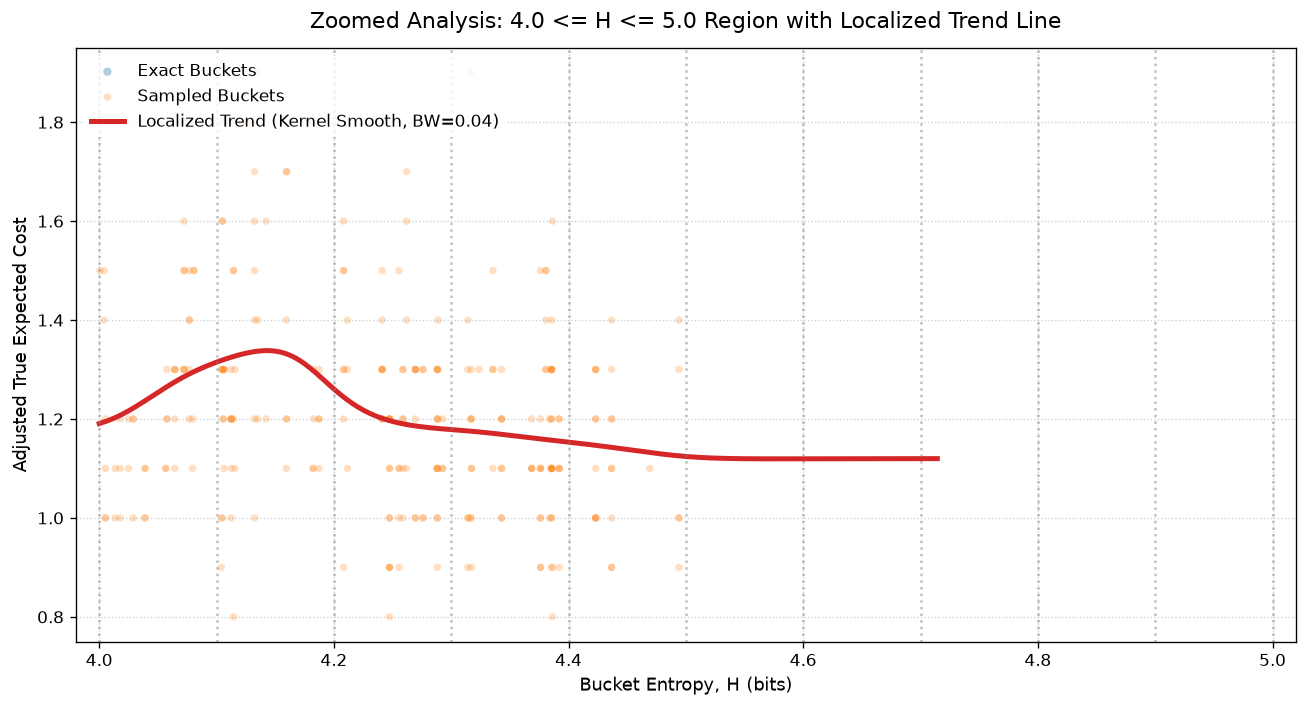

=== FREQUENCY & DENSITY METRICS FOR REGION 4.0 <= H <= 5.0 ===
Total points in region: 279 (7.02% of overall evaluation dataset)

Sub-Bin    | Count   | % Region  | % Overall  | Mean H   | Mean Cost  | Std Cost
--------------------------------------------------------------------------------
4.0 - 4.1  | 47      | 16.85   % | 1.18     % | 4.0473   | 1.2447     | 0.1886  
4.1 - 4.2  | 57      | 20.43   % | 1.43     % | 4.1323   | 1.3263     | 0.2629  
4.2 - 4.3  | 76      | 27.24   % | 1.91     % | 4.2572   | 1.1961     | 0.1829  
4.3 - 4.4  | 74      | 26.52   % | 1.86     % | 4.3614   | 1.1662     | 0.1889  
4.4 - 4.5  | 25      | 8.96    % | 0.63     % | 4.4440   | 1.1280     | 0.1568  
4.5 - 4.6  | 0       | 0.00    % | 0.00     % | 0.0000   | 0.0000     | 0.0000  
4.6 - 4.7  | 0       | 0.00    % | 0.00     % | 0.0000   | 0.0000     | 0.0000  
4.7 - 4.8  | 0       | 0.00    % | 0.00     % | 0.0000   | 0.0000     | 0.0000  
4.8 - 4.9  | 0       | 0.00    % | 0.00     % | 0.0000   | 0

: 

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Define the regions to analyze: (low_H, high_H)
target_regions = [
    (2.0, 3.0),
    (3.0, 4.0),
    (4.0, 5.0)
]

total_eval_count = len(df_eval)
bandwidth = 0.04  # Localized kernel smoothing bandwidth

for low_h, high_h in target_regions:
    # ==============================================================================
    # 1. DATA ISOLATION
    # ==============================================================================
    mask_region = (df_eval['bucket_entropy'] >= low_h) & (df_eval['bucket_entropy'] <= high_h)
    df_region = df_eval[mask_region].copy().sort_values('bucket_entropy').reset_index(drop=True)
    region_count = len(df_region)
    
    # ==============================================================================
    # 2. LOCALIZED TREND LINE (Gaussian Kernel Smoothing)
    # ==============================================================================
    grid_h = np.linspace(low_h, high_h, 400)
    smooth_y = []
    
    for h_val in grid_h:
        weights = np.exp(-0.5 * ((df_region['bucket_entropy'] - h_val) / bandwidth) ** 2)
        weight_sum = np.sum(weights)
        if weight_sum > 1e-6:
            smooth_y.append(np.average(df_region['true_cost_adj'], weights=weights))
        else:
            smooth_y.append(np.nan)
            
    smooth_y = np.array(smooth_y)
    
    # ==============================================================================
    # 3. ZOOMED PLOT
    # ==============================================================================
    plt.figure(figsize=(11, 6), dpi=120)
    
    # Scatter points in region
    mask_pri_exact = (df_primary_filtered['bucket_entropy'] >= low_h) & (df_primary_filtered['bucket_entropy'] <= high_h) & exact_primary_mask
    mask_pri_samp = (df_primary_filtered['bucket_entropy'] >= low_h) & (df_primary_filtered['bucket_entropy'] <= high_h) & (~exact_primary_mask)
    
    plt.scatter(
        df_primary_filtered.loc[mask_pri_exact, 'bucket_entropy'],
        df_primary_filtered.loc[mask_pri_exact, 'true_cost_adj'],
        alpha=0.35, color='#1f77b4', edgecolors='none', s=25, label='Exact Buckets'
    )
    
    plt.scatter(
        df_primary_filtered.loc[mask_pri_samp, 'bucket_entropy'],
        df_primary_filtered.loc[mask_pri_samp, 'true_cost_adj'],
        alpha=0.25, color='#ff7f0e', edgecolors='none', s=20, label='Sampled Buckets'
    )
    
    # Overlay Localized Trend Line
    plt.plot(
        grid_h, smooth_y, color='#d62728', linewidth=3.0,
        label=f'Localized Trend (Kernel Smooth, BW={bandwidth})'
    )
    
    # Vertical guide lines at 0.1 intervals
    for bin_start in np.arange(low_h, high_h + 0.05, 0.1):
        plt.axvline(x=bin_start, color='gray', linestyle=':', alpha=0.5)
        
    plt.title(f'Zoomed Analysis: {low_h:.1f} <= H <= {high_h:.1f} Region with Localized Trend Line', fontsize=13, pad=12)
    plt.xlabel('Bucket Entropy, H (bits)', fontsize=11)
    plt.ylabel('Adjusted True Expected Cost', fontsize=11)
    plt.xlim(low_h - 0.02, high_h + 0.02)
    
    if region_count > 0:
        y_min, y_max = df_region['true_cost_adj'].min(), df_region['true_cost_adj'].max()
        plt.ylim(max(0, y_min - 0.05), y_max + 0.05)
        
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(frameon=True, facecolor='white', edgecolor='none', loc='upper left')
    
    plt.tight_layout()
    plt.show()
    
    # ==============================================================================
    # 4. FREQUENCY & DENSITY METRICS BREAKDOWN
    # ==============================================================================
    bins = np.arange(low_h, high_h + 0.05, 0.1)
    sub_metrics = []
    
    for i in range(len(bins) - 1):
        b_low, b_high = bins[i], bins[i+1]
        if i == len(bins) - 2:
            sub = df_region[(df_region['bucket_entropy'] >= b_low) & (df_region['bucket_entropy'] <= b_high)]
        else:
            sub = df_region[(df_region['bucket_entropy'] >= b_low) & (df_region['bucket_entropy'] < b_high)]
            
        cnt = len(sub)
        pct_region = (cnt / region_count * 100) if region_count > 0 else 0.0
        pct_total = (cnt / total_eval_count * 100) if total_eval_count > 0 else 0.0
        mean_h = sub['bucket_entropy'].mean() if cnt > 0 else 0.0
        mean_cost = sub['true_cost_adj'].mean() if cnt > 0 else 0.0
        std_cost = sub['true_cost_adj'].std() if cnt > 1 else 0.0
        
        sub_metrics.append({
            'Range': f"{b_low:.1f} - {b_high:.1f}",
            'Count': cnt,
            'Pct_Region': pct_region,
            'Pct_Total': pct_total,
            'Mean_H': mean_h,
            'Mean_Cost': mean_cost,
            'Std_Cost': std_cost
        })
        
    print(f"=== FREQUENCY & DENSITY METRICS FOR REGION {low_h:.1f} <= H <= {high_h:.1f} ===")
    print(f"Total points in region: {region_count} ({(region_count / total_eval_count * 100) if total_eval_count > 0 else 0:.2f}% of overall evaluation dataset)\n")
    print(f"{'Sub-Bin':<10} | {'Count':<7} | {'% Region':<9} | {'% Overall':<10} | {'Mean H':<8} | {'Mean Cost':<10} | {'Std Cost':<8}")
    print("-" * 80)
    
    for m in sub_metrics:
        print(f"{m['Range']:<10} | {m['Count']:<7} | {m['Pct_Region']:<8.2f}% | {m['Pct_Total']:<9.2f}% | {m['Mean_H']:<8.4f} | {m['Mean_Cost']:<10.4f} | {m['Std_Cost']:<8.4f}")
    
    print("\n" + "=" * 80 + "\n")

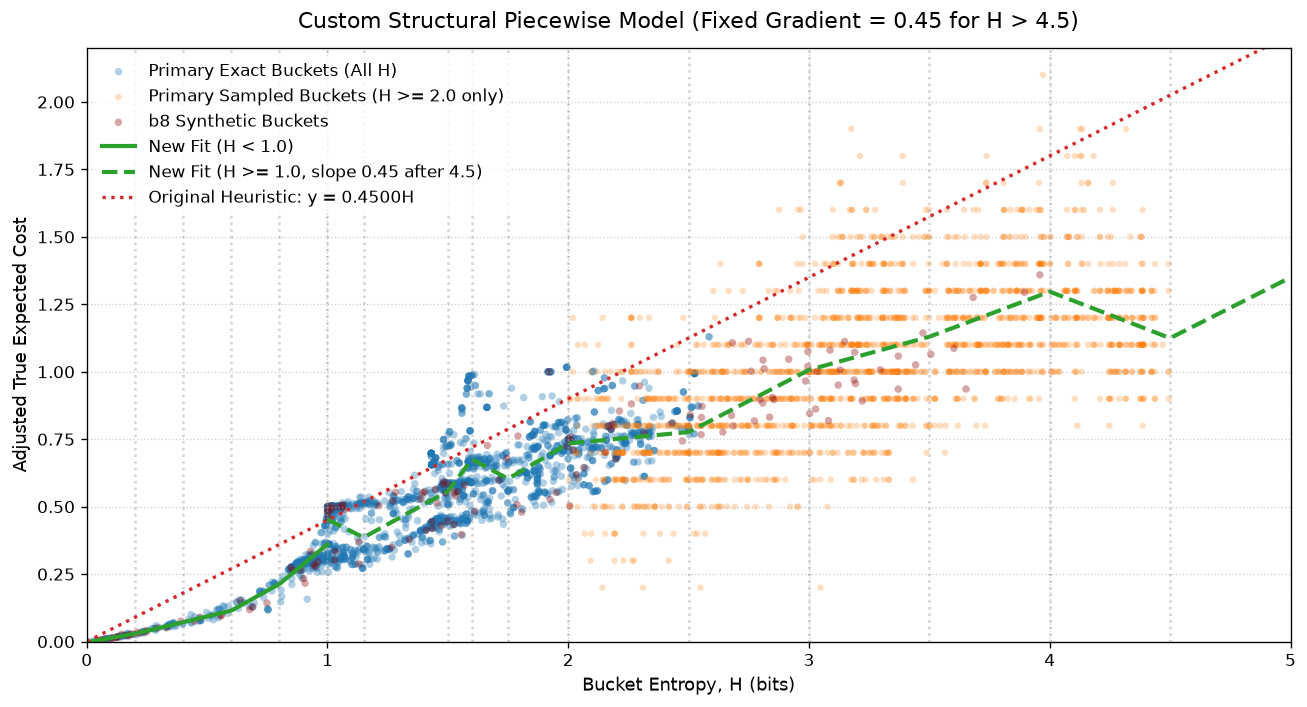

=== FINAL STRUCTURAL PIECEWISE MODEL FORMULAS & REGION BUCKET COUNTS ===
  0.00 <= H < 0.20 : E_adj = 0.1590 * H + -0.0026   | Buckets: 45
  0.20 <= H < 0.40 : E_adj = 0.2123 * H + -0.0133   | Buckets: 41
  0.40 <= H < 0.60 : E_adj = 0.2147 * H + -0.0142   | Buckets: 32
  0.60 <= H < 0.80 : E_adj = 0.4929 * H + -0.1811   | Buckets: 36
  0.80 <= H < 1.00 : E_adj = 0.7394 * H + -0.3783   | Buckets: 205
  1.00 <= H < 1.15 : E_adj = -0.4466 * H + 0.8995   | Buckets: 307
  1.15 <= H < 1.50 : E_adj = 0.4893 * H + -0.1768   | Buckets: 408
  1.50 <= H < 1.60 : E_adj = 1.1866 * H + -1.2228   | Buckets: 236
  1.60 <= H < 1.75 : E_adj = -0.4829 * H + 1.4484   | Buckets: 158
  1.75 <= H < 2.00 : E_adj = 0.5240 * H + -0.3136   | Buckets: 257
  2.00 <= H < 2.50 : E_adj = 0.0844 * H + 0.5655   | Buckets: 612
  2.50 <= H < 3.00 : E_adj = 0.4606 * H + -0.3750   | Buckets: 433
  3.00 <= H < 3.50 : E_adj = 0.2461 * H + 0.2687   | Buckets: 549
  3.50 <= H < 4.00 : E_adj = 0.3342 * H + -0.0396   | Buckets:

In [82]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. DATA PREPARATION & FILTERING
# ==============================================================================
# Identify exact vs sampled buckets in primary dataset
exact_primary_mask = df_primary['bucket_raw_size'] == df_primary['bucket_eff_size']

# Filter out randomly sampled points for H < 2.0 (Keep exact buckets for H < 2.0, keep ALL buckets for H >= 2.0)
df_primary_filtered = df_primary[
    (df_primary['bucket_entropy'] >= 2.0) | exact_primary_mask
].copy()

# Combine primary filtered data with b8 synthetic dataset (b8 data consists of exact H < 1.0 buckets)
df_eval = pd.concat([
    df_primary_filtered[['bucket_entropy', 'true_cost_adj']],
    df_b8[['bucket_entropy', 'true_cost_adj']]
], ignore_index=True)

# Define Knots according to requested custom boundary rules
LOW_KNOTS = [0.2, 0.4, 0.6, 0.8]
HIGH_KNOTS = [1.15, 1.5, 1.6, 1.75, 2.0, 2.5, 3.0, 3.5, 4.0]  # Splits up to 4.5 (gradient 0.45 forced after 4.5)

# ==============================================================================
# 2. MODEL FITTING
# ==============================================================================
# A. Fit Low-Entropy Connected Model (0 <= H < 1.0, Knots every 0.2)
df_fit_low = df_eval[df_eval['bucket_entropy'] < 1.0]
x_low = df_fit_low['bucket_entropy'].values
y_low = df_fit_low['true_cost_adj'].values

X_low_cols = [np.ones_like(x_low), x_low] + [np.maximum(0, x_low - k) for k in LOW_KNOTS]
X_low = np.column_stack(X_low_cols)

beta_low, _, _, _ = np.linalg.lstsq(X_low, y_low, rcond=None)

# B. Fit High-Entropy Connected Model (H >= 1.0, forced gradient of 0.45 for H > 4.5)
df_fit_high = df_eval[df_eval['bucket_entropy'] >= 1.0]
x_high = df_fit_high['bucket_entropy'].values
y_high = df_fit_high['true_cost_adj'].values

# Cap x at 4.5 and adjust target variable so slope above 4.5 is constrained to exactly 0.45
x_high_cap = np.minimum(x_high, 4.5)
y_high_adj = y_high - 0.45 * np.maximum(0, x_high - 4.5)

X_high_cols = [np.ones_like(x_high_cap), x_high_cap] + [np.maximum(0, x_high_cap - k) for k in HIGH_KNOTS]
X_high = np.column_stack(X_high_cols)

beta_high, _, _, _ = np.linalg.lstsq(X_high, y_high_adj, rcond=None)

# ==============================================================================
# 3. PREDICTION FUNCTIONS
# ==============================================================================
def predict_new_model(h_array):
    """Custom Piecewise Model: Discontinuous at H=1.0, fixed gradient = 0.45 for H > 4.5."""
    h_array = np.asarray(h_array, dtype=np.float64)
    y_pred = np.zeros_like(h_array)
    low_mask = h_array < 1.0
    
    # Low H (< 1.0) predictions
    if np.any(low_mask):
        x_sub = h_array[low_mask]
        X_sub_cols = [np.ones_like(x_sub), x_sub] + [np.maximum(0, x_sub - k) for k in LOW_KNOTS]
        X_sub = np.column_stack(X_sub_cols)
        y_pred[low_mask] = X_sub @ beta_low
        
    # High H (>= 1.0) predictions
    high_mask = ~low_mask
    if np.any(high_mask):
        x_sub = h_array[high_mask]
        x_cap = np.minimum(x_sub, 4.5)
        X_sub_cols = [np.ones_like(x_cap), x_cap] + [np.maximum(0, x_cap - k) for k in HIGH_KNOTS]
        X_sub = np.column_stack(X_sub_cols)
        y_pred[high_mask] = (X_sub @ beta_high) + 0.45 * np.maximum(0, x_sub - 4.5)
        
    return y_pred

def predict_orig_heuristic(h_array):
    """Original Heuristic: E = 0.45 * H"""
    return 0.45 * h_array

# Compute predictions across evaluation dataset
h_eval = df_eval['bucket_entropy'].values
y_actual = df_eval['true_cost_adj'].values

y_pred_new = predict_new_model(h_eval)
y_pred_orig = predict_orig_heuristic(h_eval)

# ==============================================================================
# 4. PLOTTING
# ==============================================================================
plt.figure(figsize=(11, 6), dpi=120)

# Filtered Primary Scatter
df_pri_exact = df_primary[exact_primary_mask]
df_pri_sampled_h2 = df_primary[(~exact_primary_mask) & (df_primary['bucket_entropy'] >= 2.0)]

plt.scatter(
    df_pri_exact['bucket_entropy'],
    df_pri_exact['true_cost_adj'],
    alpha=0.35,
    color='#1f77b4',
    edgecolors='none',
    s=20,
    label='Primary Exact Buckets (All H)'
)

plt.scatter(
    df_pri_sampled_h2['bucket_entropy'],
    df_pri_sampled_h2['true_cost_adj'],
    alpha=0.25,
    color='#ff7f0e',
    edgecolors='none',
    s=15,
    label='Primary Sampled Buckets (H >= 2.0 only)'
)

plt.scatter(
    df_b8['bucket_entropy'],
    df_b8['true_cost_adj'],
    alpha=0.35,
    color='#8b0000',
    edgecolors='none',
    s=20,
    label='b8 Synthetic Buckets'
)

# Plot Model Lines
grid_low = np.linspace(0.0, 0.999, 300)
grid_high = np.linspace(1.0, 5.0, 500)

plt.plot(
    grid_low,
    predict_new_model(grid_low),
    color='#2ca02c',
    linewidth=2.5,
    label='New Fit (H < 1.0)'
)

plt.plot(
    grid_high,
    predict_new_model(grid_high),
    color='#2ca02c',
    linestyle='--',
    linewidth=2.5,
    label='New Fit (H >= 1.0, slope 0.45 after 4.5)'
)

grid_full = np.linspace(0.0, 5.0, 300)
plt.plot(
    grid_full,
    predict_orig_heuristic(grid_full),
    color='#d62728',
    linestyle=':',
    linewidth=2.0,
    label='Original Heuristic: y = 0.4500H'
)

# Vertical boundary lines at knots and structural splits
all_knots = sorted(list(set(LOW_KNOTS + [1.00] + HIGH_KNOTS + [4.50])))
for knot in all_knots:
    plt.axvline(x=knot, color='gray', linestyle=':', alpha=0.35)

# Formatting
plt.title('Custom Structural Piecewise Model (Fixed Gradient = 0.45 for H > 4.5)', fontsize=13, pad=12)
plt.xlabel('Bucket Entropy, H (bits)', fontsize=11)
plt.ylabel('Adjusted True Expected Cost', fontsize=11)

plt.xlim(0.0, 5.0)
plt.ylim(0.0, 2.2)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', edgecolor='none', loc='upper left')

plt.tight_layout()
plt.show()

# ==============================================================================
# 5. METRICS & FORMULA EXTRACTION WITH BUCKET COUNTS
# ==============================================================================
def compute_metrics(y_true, y_pred):
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mae = np.mean(np.abs(y_true - y_pred))
    max_err = np.max(np.abs(y_true - y_pred))
    
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - (np.sum((y_true - y_pred) ** 2) / ss_tot) if ss_tot > 1e-9 else 0.0
    return rmse, mae, r2, max_err

print("=== FINAL STRUCTURAL PIECEWISE MODEL FORMULAS & REGION BUCKET COUNTS ===")

# Low-Entropy Formulas Extraction
b0, b1 = beta_low[0], beta_low[1]
gammas_low = beta_low[2:]

low_bounds = [0.0] + LOW_KNOTS + [1.0]
cur_m, cur_c = b1, b0
for i in range(len(low_bounds) - 1):
    low_b, high_b = low_bounds[i], low_bounds[i+1]
    cnt = np.sum((df_eval['bucket_entropy'] >= low_b) & (df_eval['bucket_entropy'] < high_b))
    print(f"  {low_b:.2f} <= H < {high_b:.2f} : E_adj = {cur_m:.4f} * H + {cur_c:.4f}   | Buckets: {cnt}")
    if i < len(gammas_low):
        g = gammas_low[i]
        k = LOW_KNOTS[i]
        cur_m += g
        cur_c -= g * k

# High-Entropy Formulas Extraction
bh0, bh1 = beta_high[0], beta_high[1]
gammas_high = beta_high[2:]

high_bounds = [1.0] + HIGH_KNOTS + [4.5, 999.0]
cur_m, cur_c = bh1, bh0
for i in range(len(high_bounds) - 1):
    low_b, high_b = high_bounds[i], high_bounds[i+1]
    
    if high_b == 999.0:
        cnt = np.sum(df_eval['bucket_entropy'] >= low_b)
        c_forced = (cur_m * 4.5 + cur_c) - 0.45 * 4.5
        m_forced = 0.4500
        print(f"  H >= {low_b:.2f}       : E_adj = {m_forced:.4f} * H + {c_forced:.4f}   | Buckets: {cnt}")
    else:
        cnt = np.sum((df_eval['bucket_entropy'] >= low_b) & (df_eval['bucket_entropy'] < high_b))
        print(f"  {low_b:.2f} <= H < {high_b:.2f} : E_adj = {cur_m:.4f} * H + {cur_c:.4f}   | Buckets: {cnt}")
        if i < len(gammas_high):
            g = gammas_high[i]
            k = HIGH_KNOTS[i]
            cur_m += g
            cur_c -= g * k

print()

# --- COMPARISON 1: OVERALL DATASET ---
print("=== OVERALL MODEL PERFORMANCE (ALL FILTERED H >= 0) ===")
print(f"{'Model':<28} | {'RMSE':<8} | {'MAE':<8} | {'R2':<8} | {'Max Error':<10}")
print("-" * 72)

r_new, m_new, r2_new, max_new = compute_metrics(y_actual, y_pred_new)
r_orig, m_orig, r2_orig, max_orig = compute_metrics(y_actual, y_pred_orig)

print(f"{'New Custom Piecewise Model':<28} | {r_new:<8.4f} | {m_new:<8.4f} | {r2_new:<8.4f} | {max_new:<10.4f}")
print(f"{'Original Heuristic (0.45H)':<28} | {r_orig:<8.4f} | {m_orig:<8.4f} | {r2_orig:<8.4f} | {max_orig:<10.4f}\n")

# --- COMPARISON 2: HIGH ENTROPY (H >= 1.0) COMPARISON ---
mask_h1 = h_eval >= 1.0
y_act_h1 = y_actual[mask_h1]
h_h1 = h_eval[mask_h1]

y_pred_new_h1 = predict_new_model(h_h1)
y_pred_orig_h1 = predict_orig_heuristic(h_h1)

print("=== HIGH-ENTROPY MODEL PERFORMANCE COMPARISON (H >= 1.0) ===")
print(f"{'Model':<28} | {'RMSE':<8} | {'MAE':<8} | {'R2':<8} | {'Max Error':<10}")
print("-" * 72)

r1, m1, r2_1, max1 = compute_metrics(y_act_h1, y_pred_new_h1)
r2, m2, r2_2, max2 = compute_metrics(y_act_h1, y_pred_orig_h1)

print(f"{'New Structural Piecewise Fit':<28} | {r1:<8.4f} | {m1:<8.4f} | {r2_1:<8.4f} | {max1:<10.4f}")
print(f"{'Original Heuristic (0.45H)':<28} | {r2:<8.4f} | {m2:<8.4f} | {r2_2:<8.4f} | {max2:<10.4f}\n")

# --- COMPARISON 3: DETAILED BREAKDOWN BY SPECIFIED SEGMENTS ---
ranges = [
    ('0.0 - 0.2', 0.0, 0.2), ('0.2 - 0.4', 0.2, 0.4), ('0.4 - 0.6', 0.4, 0.6), ('0.6 - 0.8', 0.6, 0.8), ('0.8 - 1.0', 0.8, 1.0),
    ('1.0 - 1.15', 1.0, 1.15), ('1.15 - 1.5', 1.15, 1.5), ('1.5 - 1.6', 1.5, 1.6), ('1.6 - 1.75', 1.6, 1.75), ('1.75 - 2.0', 1.75, 2.0),
    ('2.0 - 2.5', 2.0, 2.5), ('2.5 - 3.0', 2.5, 3.0), ('3.0 - 3.5', 3.0, 3.5), ('3.5 - 4.0', 3.5, 4.0), ('4.0 - 4.5', 4.0, 4.5),
    ('4.5+', 4.5, 999.0)
]

print("=== NEW MODEL DETAILED BREAKDOWN BY SPECIFIED SEGMENTS ===")
print(f"{'Range':<11} | {'Buckets':<8} | {'RMSE':<8} | {'MAE':<8} | {'R2':<8} | {'Max Error':<10}")
print("-" * 67)

for label, low, high in ranges:
    sub_mask = (df_eval['bucket_entropy'] >= low) & (df_eval['bucket_entropy'] < high) if high != 999.0 else (df_eval['bucket_entropy'] >= low)
    sub_y = df_eval.loc[sub_mask, 'true_cost_adj'].values
    sub_h = df_eval.loc[sub_mask, 'bucket_entropy'].values
    count = len(sub_y)
    
    if count > 0:
        sub_pred = predict_new_model(sub_h)
        r, m, r2_val, max_e = compute_metrics(sub_y, sub_pred)
        print(f"{label:<11} | {count:<8} | {r:<8.4f} | {m:<8.4f} | {r2_val:<8.4f} | {max_e:<10.4f}")
    else:
        print(f"{label:<11} | {0:<8} | N/A      | N/A      | N/A      | N/A")

In [58]:
import numpy as np
import pandas as pd
import scipy.stats as stats
from pathlib import Path

# 1. Load and filter dataset for H > 4.0
file_path = Path('../data/sampled_bucket_evaluations.csv')
df = pd.read_csv(file_path)
df['true_cost_adj'] = df['true_expected_cost'] - 3.0

df_tail = df[df['bucket_entropy'] > 4.0].copy()
x_tail = df_tail['bucket_entropy'].values
y_tail = df_tail['true_cost_adj'].values

n_samples = len(df_tail)
print(f"Total samples in tail (H > 4.0): {n_samples}\n")

# ==========================================
# TEST 1: OLS Regression & p-value Test
# ==========================================
slope, intercept, r_value, p_value, std_err = stats.linregress(x_tail, y_tail)

print("=== 1. OLS HYPOTHESIS TEST ON TAIL SLOPE ===")
print(f"Fitted Slope (beta_1) : {slope:.4f}")
print(f"Standard Error        : {std_err:.4f}")
print(f"p-value               : {p_value:.4f}")
if p_value > 0.05:
    print("Verdict               : NOT statistically significant (p > 0.05). Slope is consistent with noise.\n")
else:
    print("Verdict               : Statistically significant (p <= 0.05).\n")

# ==========================================
# TEST 2: Bootstrap Resampling (1,000 Replicates)
# ==========================================
n_bootstraps = 1000
boot_slopes = []

np.random.seed(42)
for _ in range(n_bootstraps):
    # Resample with replacement
    boot_idx = np.random.choice(n_samples, size=n_samples, replace=True)
    x_boot, y_boot = x_tail[boot_idx], y_tail[boot_idx]
    
    # Fit line
    if len(np.unique(x_boot)) > 1:
        b_slope, _ = np.polyfit(x_boot, y_boot, 1)
        boot_slopes.append(b_slope)

ci_lower = np.percentile(boot_slopes, 2.5)
ci_upper = np.percentile(boot_slopes, 97.5)

print("=== 2. BOOTSTRAP 95% CONFIDENCE INTERVAL ===")
print(f"Mean Bootstrap Slope : {np.mean(boot_slopes):.4f}")
print(f"95% CI Range         : [{ci_lower:.4f}, {ci_upper:.4f}]")
if ci_lower <= 0 <= ci_upper:
    print("Verdict              : CI includes 0.0. The tail slope sign cannot be reliably determined.\n")
else:
    print("Verdict              : CI does not include 0.0.\n")

# ==========================================
# TEST 3: Random 50/50 Subsample Splits (Your Proposed Idea)
# ==========================================
print("=== 3. RANDOM 50/50 SUBSAMPLE SPLITS ===")
print(f"{'Split #':<8} | {'Subset 1 Slope':<15} | {'Subset 2 Slope':<15} | {'Difference':<10}")
print("-" * 55)

for split_id in range(1, 6):
    # Randomly partition tail data into two equal halves
    indices = np.random.permutation(n_samples)
    half = n_samples // 2
    
    idx1, idx2 = indices[:half], indices[half:]
    
    s1, _ = np.polyfit(x_tail[idx1], y_tail[idx1], 1)
    s2, _ = np.polyfit(x_tail[idx2], y_tail[idx2], 1)
    
    print(f"Split {split_id:<2} | {s1:<15.4f} | {s2:<15.4f} | {abs(s1 - s2):<10.4f}")

Total samples in tail (H > 4.0): 279

=== 1. OLS HYPOTHESIS TEST ON TAIL SLOPE ===
Fitted Slope (beta_1) : -0.3841
Standard Error        : 0.0939
p-value               : 0.0001
Verdict               : Statistically significant (p <= 0.05).

=== 2. BOOTSTRAP 95% CONFIDENCE INTERVAL ===
Mean Bootstrap Slope : -0.3836
95% CI Range         : [-0.5704, -0.2038]
Verdict              : CI does not include 0.0.

=== 3. RANDOM 50/50 SUBSAMPLE SPLITS ===
Split #  | Subset 1 Slope  | Subset 2 Slope  | Difference
-------------------------------------------------------
Split 1  | -0.4296         | -0.3247         | 0.1049    
Split 2  | -0.3236         | -0.4359         | 0.1123    
Split 3  | -0.3082         | -0.4629         | 0.1546    
Split 4  | -0.3224         | -0.4286         | 0.1063    
Split 5  | -0.3700         | -0.3912         | 0.0212    


=== HIGH-ENTROPY TAIL DIAGNOSTICS ===
Total sub-buckets evaluated : 179,421
Max Entropy encountered      : 6.0695 bits
90th Percentile              : 1.9399 bits
95th Percentile              : 2.5664 bits
99th Percentile              : 3.8745 bits
99.9th Percentile            : 5.1293 bits
99.99th Percentile            : 5.7617 bits
--------------------------------------------------
Buckets with H >= 3.0        : 5,563 (3.101%)
Buckets with H >= 4.0        : 1,481 (0.8254%)
Buckets with H >= 4.5        : 570 (0.3177%)


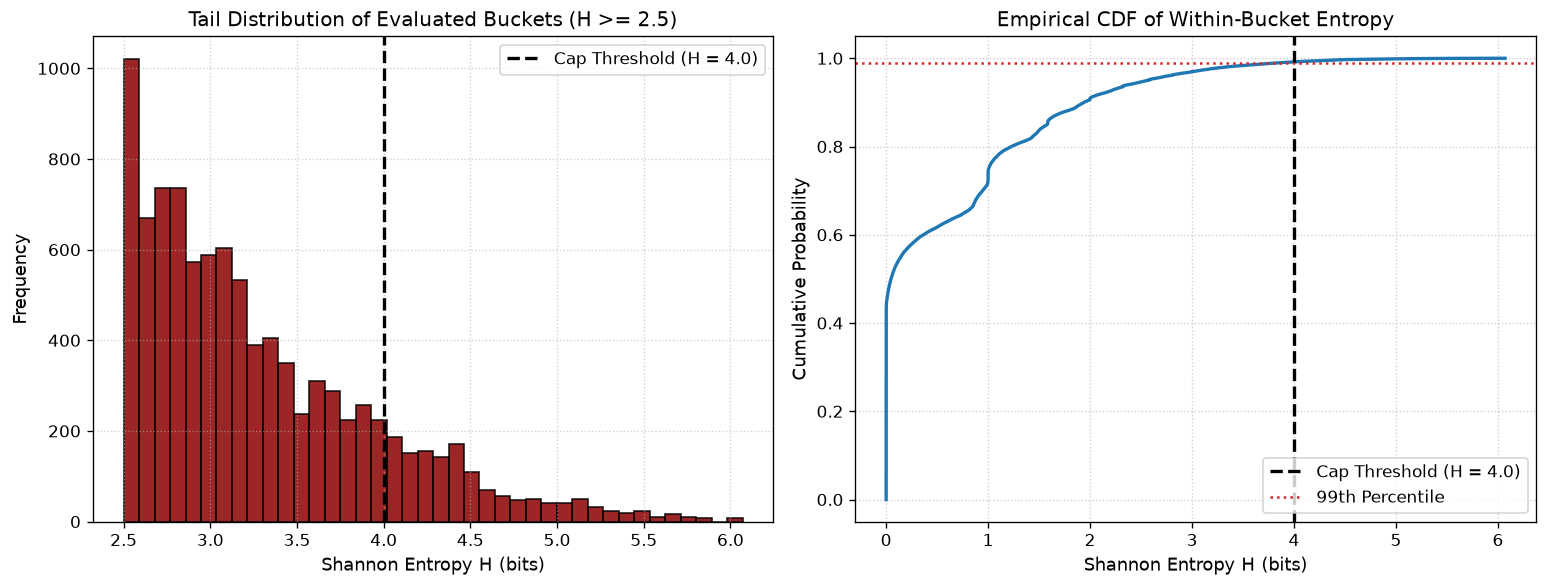

In [61]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# 1. Reload the bucket entropy log dataset
log_file = Path("../data/repeat_era_bucket_entropy_log.csv")
df = pd.read_csv(log_file)

# 2. Parse JSON strings and flatten into DataFrame
all_buckets = []
for raw_str in df["bucket_details_raw"].dropna():
    buckets = json.loads(raw_str)
    all_buckets.extend(buckets)

df_buckets = pd.DataFrame(all_buckets)
entropies = df_buckets["h"]
total_count = len(entropies)

# 3. Calculate key tail statistics
max_h = entropies.max()
p90 = np.percentile(entropies, 90)
p95 = np.percentile(entropies, 95)
p99 = np.percentile(entropies, 99)
p99_9 = np.percentile(entropies, 99.9)
p99_99 = np.percentile(entropies, 99.99)

count_3_plus = (entropies >= 3.0).sum()
count_4_plus = (entropies >= 4.0).sum()
count_4_5_plus = (entropies >= 4.5).sum()

print("=== HIGH-ENTROPY TAIL DIAGNOSTICS ===")
print(f"Total sub-buckets evaluated : {total_count:,}")
print(f"Max Entropy encountered      : {max_h:.4f} bits")
print(f"90th Percentile              : {p90:.4f} bits")
print(f"95th Percentile              : {p95:.4f} bits")
print(f"99th Percentile              : {p99:.4f} bits")
print(f"99.9th Percentile            : {p99_9:.4f} bits")
print(f"99.99th Percentile            : {p99_99:.4f} bits")
print("-" * 50)
print(f"Buckets with H >= 3.0        : {count_3_plus:,} ({count_3_plus / total_count * 100:.3f}%)")
print(f"Buckets with H >= 4.0        : {count_4_plus:,} ({count_4_plus / total_count * 100:.4f}%)")
print(f"Buckets with H >= 4.5        : {count_4_5_plus:,} ({count_4_5_plus / total_count * 100:.4f}%)")

# 4. Visualizations: Tail Histogram & Cumulative Distribution Function (CDF)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=120)

# Plot 1: Zoomed Tail Histogram (H >= 2.5)
tail_mask = entropies >= 2.5
ax1.hist(
    entropies[tail_mask],
    bins=40,
    color="#8b0000",
    alpha=0.85,
    edgecolor="black"
)
ax1.axvline(4.0, color="black", linestyle="--", linewidth=2, label="Cap Threshold (H = 4.0)")
ax1.set_title("Tail Distribution of Evaluated Buckets (H >= 2.5)", fontsize=12)
ax1.set_xlabel("Shannon Entropy H (bits)", fontsize=11)
ax1.set_ylabel("Frequency", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper right")

# Plot 2: Empirical CDF
sorted_h = np.sort(entropies)
cdf = np.arange(1, total_count + 1) / total_count

ax2.plot(sorted_h, cdf, color="#1f77b4", linewidth=2)
ax2.axvline(4.0, color="black", linestyle="--", linewidth=2, label="Cap Threshold (H = 4.0)")
ax2.axhline(0.99, color="#d62728", linestyle=":", label="99th Percentile")
ax2.set_title("Empirical CDF of Within-Bucket Entropy", fontsize=12)
ax2.set_xlabel("Shannon Entropy H (bits)", fontsize=11)
ax2.set_ylabel("Cumulative Probability", fontsize=11)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()